# Лабораторная работа № 4. Автокодировщики и латентные пространства

**Тема:** обучение представлений данных, автокодировщики, вариационные автокодировщики и условная генерация изображений.

**Цель:** познакомиться с обучением нейросетей без явного предсказания классов, научиться строить латентные представления и изучить основы генеративных моделей.

В предыдущих работах мы решали задачи классификации: подавали изображение на вход сети и обучали её предсказывать метку. Теперь изменим постановку задачи. Сеть будет получать само изображение в качестве цели обучения: сначала сжимать его в компактное представление, а затем восстанавливать по этому представлению.

Последовательно рассмотрим обычный автокодировщик (AE), вариационный автокодировщик (VAE) и условный вариационный автокодировщик (CVAE).

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в предыдущих работах

В лабораторных № 1–3 мы обучали сети классифицировать изображения. Для этого использовали размеченные данные: каждому изображению соответствовала метка класса. Последний слой выдавал десять логитов, а `CrossEntropyLoss` сравнивала их с правильной меткой.

Но не для каждой задачи требуется целевая метка. Часто полезно научиться получать компактное представление объекта, сохраняющее важную информацию о нём. Такое представление можно использовать для визуализации, поиска похожих объектов, последующей классификации или генерации новых данных.

**Главный вопрос:** может ли сеть научиться выделять полезные признаки изображения, если в качестве цели обучения ей предъявляется само изображение?

## Избыточность информации и обучение представлений

Информация зачастую содержит **избыточность**: не все её элементы независимы друг от друга, а часть данных можно восстановить или представить через другие. Например, соседние пиксели изображения связаны между собой, штрихи образуют непрерывные линии, а объекты имеют общую структуру. Поэтому для описания содержимого часто не требуется хранить каждый элемент независимо.

Сжимать данные можно с помощью классических алгоритмов (например, JPEG), а можно использовать нейросетевые методы, которые учатся находить компактные представления данных.

Обучение таких компактных представлений называют *representation learning* - обучением представлений.

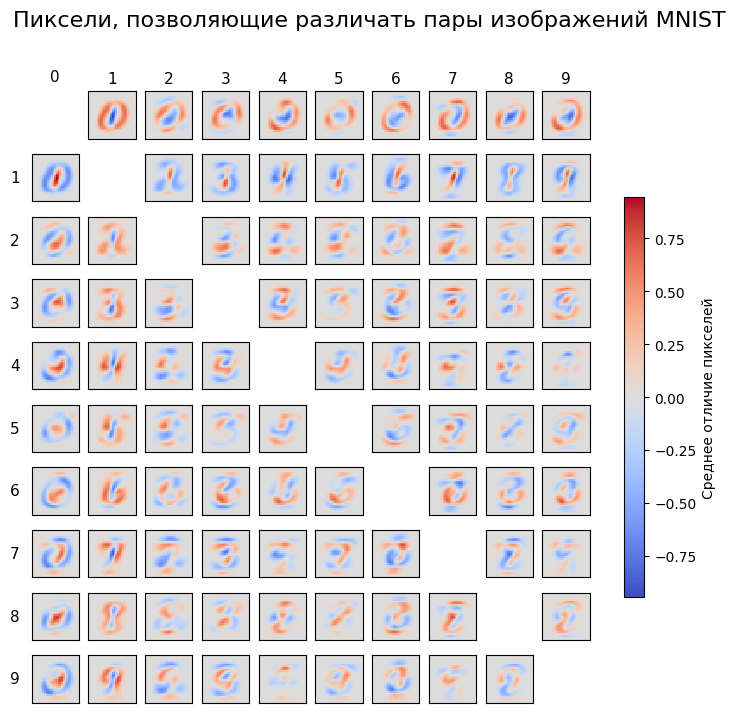

In [3]:
# Визуализация пикселей, позволяющих различать пары изображений MNIST.

from pathlib import Path

from matplotlib import pyplot as plt
import numpy as np
from torchvision import datasets
from matplotlib.colors import TwoSlopeNorm

DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

# Загружаем MNIST.
mnist = datasets.MNIST(root=DATA_DIR, train=True, download=True)

images = mnist.data.float() / 255.0
labels = mnist.targets

# Вычисляем среднее изображение для каждой цифры.
mean_images = torch.stack([images[labels == d].mean(dim=0) for d in range(10)])

mean_images = mean_images.numpy()

# Строим разности средних изображений.
differences = np.zeros((10, 10, 28, 28))

for compare1 in range(10):
    for compare2 in range(10):
        if compare1 != compare2:
            differences[compare2, compare1] = (
                mean_images[compare2] - mean_images[compare1]
            )

# Строим попарное сравнение средних цифр.
fig, axes = plt.subplots(10, 10, figsize=(9, 8), sharex=True, sharey=True)

# Симметричная шкала относительно нуля.
vmax = np.abs(differences).max()
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

for compare2 in range(10):
    for compare1 in range(10):
        ax: plt.Axes = axes[compare2, compare1]

        # Номера цифр в заголовках и строках.
        if compare2 == 0:
            ax.set_title(str(compare1), fontsize=11)

        if compare1 == 0:
            ax.set_ylabel(
                str(compare2), fontsize=11, rotation=0, labelpad=12, va="center"
            )

        # Пропускам диагональные элементы матрицы.
        if compare1 == compare2:
            ax.axis("off")
            continue

        im = ax.imshow(
            differences[compare2, compare1],
            cmap="coolwarm",
            norm=norm,
            interpolation="nearest",
        )

        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("Пиксели, позволяющие различать пары изображений MNIST", fontsize=16)

# Общая цветовая шкала.
fig.colorbar(
    im, ax=axes.ravel().tolist(), shrink=0.65, label="Среднее отличие пикселей"
)

plt.show()

Цвет каждого пикселя показывает разницу между средними значениями соответствующих пикселей для двух цифр. Красный цвет означает, что пиксель имеет большее значение для цифры, указанной в строке, синий - для цифры, указанной в столбце, а белый - что значения практически не различаются. Таким образом, цвет показывает, в каких областях изображения две цифры имеют наиболее заметные различия.

Матрица демонстрирует, что для классификации цифр не обязательно анализировать все 784 пикселя независимо. Многие пиксели имеют сходные значения для разных цифр, поскольку отражают общие элементы их структуры, например толщину штрихов или особенности фона. При этом наиболее выраженные цветовые области указывают на участки, содержащие отличительные признаки цифр. Следовательно, значительная часть информации в изображении избыточна, а для распознавания цифр может быть достаточно компактного представления, сохраняющего наиболее существенные структурные особенности.

**Небольшое исследование.** Рассмотрите матрицу и найдите пары цифр, средние изображения которых наиболее похожи друг на друга (например, 3 и 5, 4 и 9, 1 и 7). Для каждой выбранной пары проанализируйте цветовые области и определите, какие именно особенности написания позволяют отличить одну цифру от другой.

## Автокодировщик: encoder и decoder

**Автокодировщик** (*autoencoder, AE*) - нейросеть, обучаемая восстанавливать входные данные. Она состоит из двух частей:

- **Encoder** преобразует исходный объект в компактный вектор признаков.
- **Decoder** по этому вектору восстанавливает объект исходного формата.

Обозначим входной объект через $x$, кодировщик через $f_\theta$, декодировщик через $g_\phi$:

$$
z=f_\theta(x),\qquad \hat{x}=g_\phi(z).
$$

Вектор $z$ называется **латентным представлением** или латентным кодом. Восстановленный объект $\hat{x}$ должен быть похож на исходный $x$. Целевой меткой здесь служит сам объект, а не его класс.

### Bottleneck - узкое место

Если не ограничивать размер промежуточного представления, сеть может научиться почти напрямую копировать вход. Поэтому вводят **bottleneck** - узкое место, через которое проходит информация.

Для MNIST вход содержит 784 значения. При `latent_dim=16` encoder отображает $\mathbb{R}^{784}\rightarrow\mathbb{R}^{16}$, а decoder восстанавливает изображение из 16 чисел.

Сжатие не означает, что сеть сохраняет каждый пиксель без потерь. Она учится сохранять информацию, достаточную для минимизации ошибки реконструкции.

**Задание:** рассчитайте коэффициент сжатия для `latent_dim = 2, 16, 32, 64`. Почему это не равно фактическому сжатию файла на диске?

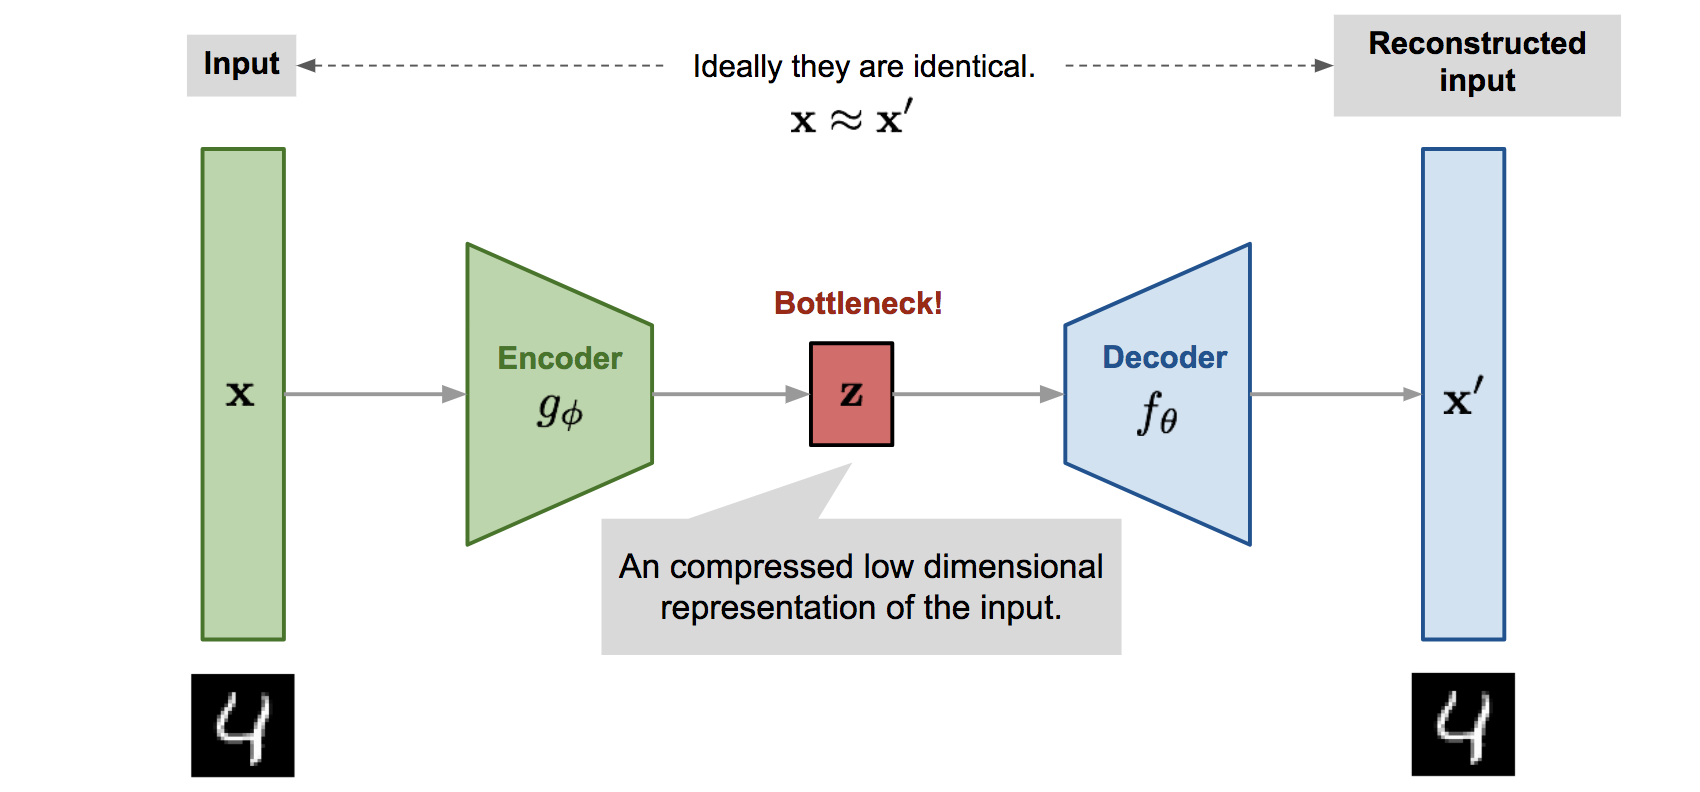

### Латентное пространство и feature extraction

Все возможные латентные векторы образуют **латентное пространство**. Каждому изображению encoder сопоставляет точку. Близкие по структуре изображения могут получать похожие коды, но это не гарантируется автоматически: геометрия зависит от архитектуры, функции потерь, размерности и обучающих данных.

Encoder можно использовать отдельно от decoder как **feature extractor**: получать векторы признаков для классификатора, кластеризации, поиска похожих изображений и визуализации. При этом encoder сам по себе не обязан предсказывать класс.

### Функция потерь реконструкции

Для обучения AE сравнивают исходное изображение $x$ и восстановленное $\hat{x}$. Один из вариантов - среднеквадратичная ошибка:

$$
\mathcal{L}_{rec}=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2.
$$

В PyTorch это `nn.MSELoss()`. В этой работе значения пикселей будут находиться в диапазоне `[0, 1]`, поэтому выходной `Sigmoid` decoder ограничит реконструкцию тем же диапазоном.

## Свёрточный автокодировщик

Для изображений удобно использовать свёрточные слои: они извлекают локальные признаки и сохраняют пространственную структуру. Encoder постепенно уменьшает разрешение и увеличивает число каналов. Полученные карты признаков преобразуются в латентный вектор.

Decoder выполняет обратную последовательность: из латентного вектора формирует карты признаков и постепенно увеличивает их разрешение. Для MNIST вход имеет форму `[B, 1, 28, 28]`; decoder должен вернуть тензор той же формы.

### Методы увеличения размера карт признаков

#### 1. Max Unpooling

`MaxPool2d` уменьшает разрешение, выбирая максимум в каждом окне. Если включить `return_indices=True`, слой также возвращает индексы позиций выбранных максимумов. `MaxUnpool2d` использует эти индексы, чтобы разместить значения обратно в соответствующих позициях карты большего размера. Остальные позиции заполняются нулями.

```python
pool = nn.MaxPool2d(2, 2, return_indices=True)
unpool = nn.MaxUnpool2d(2, 2)
pooled, indices = pool(features)
restored = unpool(pooled, indices, output_size=features.size())
```

Unpooling не является точной обратной операцией: значения, отброшенные pooling, восстановить невозможно. Он возвращает максимумы на сохранённые позиции, а не исходную карту целиком. `output_size` помогает явно задать нужную исходную форму, особенно при нечётных размерах.

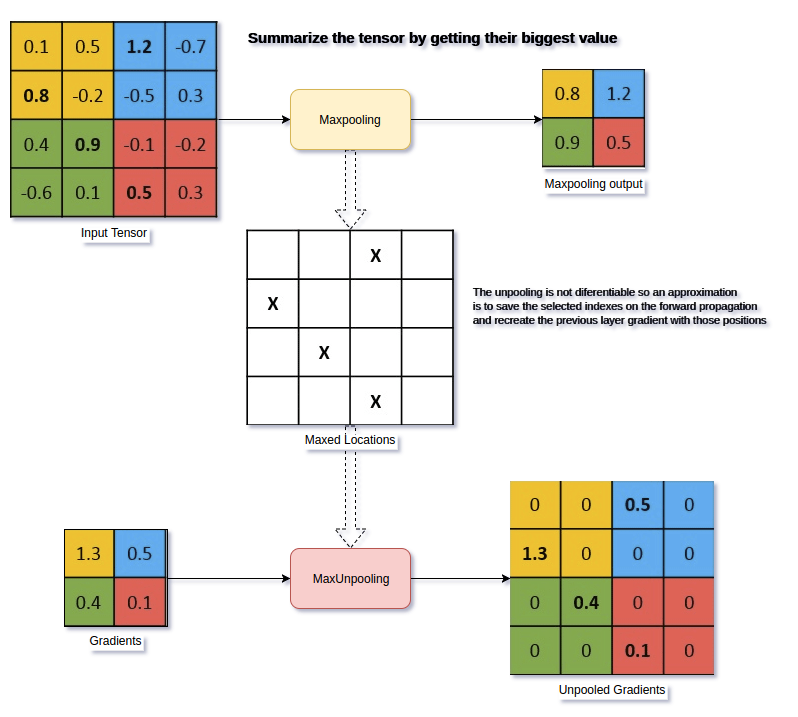

#### 2. Upsampling

Upsampling увеличивает высоту и ширину карты по правилу интерполяции. Ему не нужны индексы предыдущего pooling.

Основные варианты:
- `nearest` - ближайший сосед; значения повторяются на несколько позиций;
- `bilinear` - новые значения вычисляются как взвешенная комбинация соседних точек;
- `bicubic` - бикубическая интерполяция с более широким окружением.

Upsampling не имеет обучаемых параметров. Он лишь меняет размер карты. После него часто ставят `Conv2d`, чтобы сеть могла обработать результат интерполяции и сформировать более подходящие признаки. Интерполяция не возвращает информацию, потерянную при уменьшении разрешения.

#### 3. Transposed Convolution

`nn.ConvTranspose2d` - обучаемый слой, увеличивающий пространственное разрешение входной карты признаков. Его часто называют *deconvolution*, но это не точная обратная свёртка: слой не восстанавливает исходные данные, а учится формировать увеличенные карты признаков.

В отличие от обычной свёртки (`Conv2d`), которая обычно уменьшает пространственное разрешение при `stride > 1`, транспонированная свёртка позволяет увеличить его.

**Алгоритм работы транспонированной свёртки**

Основная идея заключается в том, что каждый элемент входной карты признаков вносит вклад в несколько элементов выходной карты. Для этого обучаемое ядро применяется к каждому входному значению, а полученные результаты складываются в соответствующих позициях выходного тензора.

Алгоритм можно представить следующим образом:

1. **Создание выходной карты.** Сначала определяется размер выходного тензора. В простейшем случае при `stride=1` и `padding=0` его пространственные размеры увеличиваются на величину ядра минус один.

2. **Обработка входных элементов.** Каждый элемент входной карты признаков умножается на все элементы обучаемого ядра. Таким образом, одно входное значение формирует небольшой фрагмент выходной карты.

3. **Размещение результатов.** Полученный фрагмент размещается в выходном тензоре. Положение фрагмента зависит от положения исходного элемента и значения `stride`.

4. **Суммирование перекрытий.** Если фрагменты, сформированные разными входными элементами, перекрываются, их значения складываются. Именно поэтому один выходной элемент может зависеть сразу от нескольких входных элементов.

5. **Добавление bias.** Если используется `bias`, к каждому элементу соответствующего выходного канала прибавляется обучаемое смещение.

**Как работают stride и padding**

- `stride` определяет шаг, с которым размещаются фрагменты ядра. При увеличении `stride` между соседними фрагментами появляется больше пространства, поэтому выходная карта становится больше.
- `padding` влияет на пространственный размер результата, определяя, какие граничные позиции учитываются при формировании выходной карты.
- `output_padding` позволяет дополнительно увеличить размер выходного тензора на одну или несколько позиций по пространственным измерениям. Он используется для устранения неоднозначности размера выхода, возникающей при обратном сопоставлении размеров свёртки.

Для квадратного ядра формула вычисления размера одной пространственной размерности выхода:

$$
H_{out}=(H_{in}-1)\cdot S-2P+D(K-1)+OP+1
$$

где:

- $H_{in}$ - размер входной карты по рассматриваемому измерению;
- $S$ - `stride`;
- $P$ - `padding`;
- $D$ - `dilation`;
- $K$ - размер ядра;
- $OP$ - `output_padding`.

Аналогично вычисляется $W_{out}$.

**Каналы и обучаемые параметры**

Как и в обычной свёртке, транспонированная свёртка использует обучаемые фильтры. Однако форма весового тензора в PyTorch отличается:

$ (C_{in}, C_{out}, K_H, K_W). $

Здесь `in_channels` задаёт число входных каналов, а `out_channels` - число выходных каналов.

При использовании `bias` количество обучаемых параметров составляет:

$$ N_{params}=C_{in}\cdot C_{out}\cdot K^2+C_{out}. $$

Например, `nn.ConvTranspose2d(32, 64, kernel_size=3)` имеет $64\cdot32\cdot3\cdot3+64=18\,496$ обучаемых параметров.

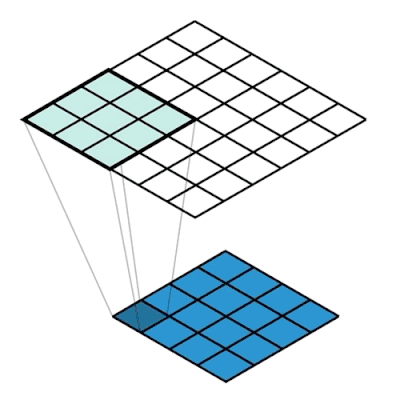

| Метод | Обучаемые параметры | Особенности |
|---|---:|---|
| MaxUnpooling | Нет | Использует индексы MaxPool; остальные позиции заполняются нулями |
| Upsampling | Нет | Интерполяция; часто используется вместе с Conv2d |
| ConvTranspose2d | Да | Учится формировать увеличенные карты признаков |

## Подготовка MNIST

Используем MNIST, как в лабораторной работе № 1. Метки понадобятся для раскраски латентных точек и анализа результатов, но **не будут подаваться в AE и VAE при обучении**.

Аугментации не используем: автокодировщик должен восстанавливать тот же объект, который получил на вход. Оставим пиксели в диапазоне `[0, 1]`. Train/validation/test разбиение фиксируем с помощью seed.

In [ ]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VALIDATION_SHARE = 0.20

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [5]:
# Загружаем MNIST без аугментаций.
# Разделяем обучающую часть MNIST на train и validation, сохраняя test отдельно.
from torch.utils.data import DataLoader, Subset, TensorDataset

train_raw = datasets.MNIST(root=DATA_DIR, train=True, download=True)
test_raw = datasets.MNIST(root=DATA_DIR, train=False, download=True)

train_full_dataset = TensorDataset(train_raw.data, train_raw.targets.long())
test_dataset = TensorDataset(test_raw.data, test_raw.targets.long())

split_generator = torch.Generator().manual_seed(SEED)
permuted_indices = torch.randperm(
    len(train_full_dataset), generator=split_generator
).tolist()

validation_size = int(len(permuted_indices) * VALIDATION_SHARE)
validation_indices = permuted_indices[:validation_size]
train_indices = permuted_indices[validation_size:]

train_dataset = Subset(train_full_dataset, train_indices)
validation_dataset = Subset(train_full_dataset, validation_indices)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 48000
Validation: 12000
Test: 10000


In [6]:
# Создаём collate_fn: он объединяет raw-изображения b переносит батч на device.
from typing import TypeAlias, Union

# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]

# Устройство можно задать строкой, объектом torch.device или индексом GPU.
DeviceLikeType: TypeAlias = Union[str, torch.device, int]


class MNISTCollator:
    """Подготавливает батч изображений Fashion-MNIST для CNN."""

    def __init__(self, device: DeviceLikeType) -> None:
        # Сохраняем целевое устройство, на котором будут выполняться преобразования.
        self.device = torch.device(device)

    def __call__(self, batch: list[TensorPair]) -> TensorPair:
        # Разделяем список элементов батча на изображения и соответствующие метки.
        images, targets = zip(*batch)

        # Объединяем изображения в тензор [B, H, W] и добавляем размерность канала.
        # Одновременно получаем форму [B, 1, H, W].
        images = torch.stack(images).unsqueeze(1)

        # Переносим изображения на выбранное устройство и преобразуем в float32.
        # Деление на 255 переводит значения пикселей из [0, 255] в [0, 1].
        images = images.to(device=self.device, dtype=torch.float32) / 255.0

        # Объединяем метки в один тензор и переносим их на то же устройство.
        targets = torch.stack(targets).to(self.device)

        # Возвращаем готовый батч признаков и меток.
        return images, targets

In [7]:
# Создаём все DataLoader с одним collator.
collator = MNISTCollator(device=device)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)

features_batch, labels_batch = next(iter(train_loader))
print("Форма признаков:", tuple(features_batch.shape))
print("Форма меток:", tuple(labels_batch.shape))
print("Тип признаков:", features_batch.dtype)
print("Тип меток:", labels_batch.dtype)

Форма признаков: (128, 1, 28, 28)
Форма меток: (128,)
Тип признаков: torch.float32
Тип меток: torch.int64


## Реализация свёрточного AE

Базовая архитектура уменьшает размер `28 → 14 → 7`. После свёрточных блоков encoder разворачивает карты `[B, 64, 7, 7]` в вектор и проецирует его в `latent_dim`. Decoder выполняет обратное преобразование.

Ваша задача - самостоятельно собрать этапы сети. Проверьте формы encoder и decoder до обучения. Не передавайте метки классов в `forward`.

In [8]:
# Вспомогательные модули исключительно для визуализации.
import torch.nn as nn


class Code(nn.Identity): ...


class Concatenate(nn.Module):
    def __init__(self, dim: int = 0):
        super().__init__()
        self.dim = dim

    def forward(
        self, tensors: tuple[torch.Tensor, ...] | list[torch.Tensor] | None
    ) -> torch.Tensor:
        return torch.cat(tensors, dim=self.dim)

In [ ]:
# Каркас AE: заполните отмеченные места.


class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim: int = 16) -> None:
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: два свёрточных блока уменьшают разрешение 28 -> 14 -> 7, каналы увеличиваются 1 -> 32 -> 64. После них идёт nn.Flatten и линейный слой.
        self.encoder_conv = nn.Sequential(...)

        # Используем вспомогательный модуль для корректного отображения с помощью visualtorch.
        self.code = Code()

        # Decoder: разворачивает вектор в карту признаков. В обратном порядке применяет nn.ConvTranspose2d: разрешение увеличивается 7 -> 14 -> 28, каналы уменьшаются 64 -> 32 -> 1.
        self.decoder_conv = nn.Sequential(
            ...,  # Линейный слой
            nn.Unflatten(1, unflattened_size=(64, 7, 7)),
            ...,  # Свёртки
            nn.Sigmoid(),
        )

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder_conv(x)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder_conv(z)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        code = self.code(self.encode(x))
        return self.decode(code)

In [10]:
ae_model = ConvAutoencoder(latent_dim=16).to(device)
example = torch.randn(4, 1, 28, 28, device=device)

with torch.inference_mode():
    z_example = ae_model.encode(example)
    reconstruction_example = ae_model(example)

print(
    "Вход:",
    tuple(example.shape),
    "код:",
    tuple(z_example.shape),
    "реконструкция:",
    tuple(reconstruction_example.shape),
)

print(
    "Обучаемые параметры:",
    sum(p.numel() for p in ae_model.parameters() if p.requires_grad),
)

Вход: (4, 1, 28, 28) код: (4, 16) реконструкция: (4, 1, 28, 28)
Обучаемые параметры: 155633


In [ ]:
%pip install aggdraw git+https://github.com/atrepalin/visualtorch -qU --no-deps

In [86]:
from collections import defaultdict
import visualtorch

color_map = defaultdict(dict)


color_map[visualtorch.Input]["fill"] = "#E69F00"  # Orange
color_map[Code]["fill"] = "#56B4E9"  # Sky Blue
color_map[Concatenate]["fill"] = "#0000FF"  # Blue
color_map[nn.Conv2d]["fill"] = "#009E73"  # Bluish Green
color_map[nn.ConvTranspose2d]["fill"] = "#F0E442"  # Yellow
color_map[nn.ReLU]["fill"] = "#0072B2"  # Blue
color_map[nn.Linear]["fill"] = "#E15759"  # Coral
color_map[nn.MaxPool2d]["fill"] = "#AEC7E8"  # Light Blue
color_map[nn.Embedding]["fill"] = "#EB96EB"  # Lavender
color_map[nn.Sigmoid]["fill"] = "#85B6B2"  # Teal
color_map[nn.Flatten]["fill"] = "#B07AA1"  # Purple
color_map[nn.Unflatten]["fill"] = "#9400D3"  # Dark Violet

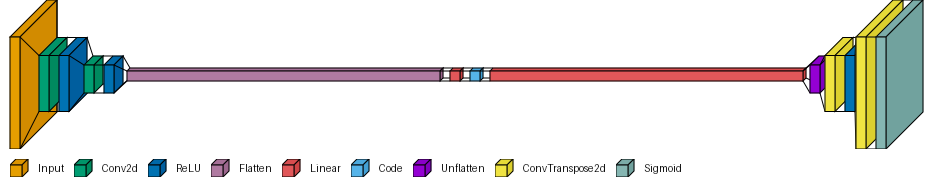

In [11]:
img = visualtorch.render(
    ae_model.cpu(),
    input_shape=(4, 1, 28, 28),
    style="flow",
    legend=True,
    scale_xy=4,
    color_map=color_map,
)

img

## Обучение AE

Во всех предыдущих работах мы использовали общий класс `LitModel` для обучения моделей. Данный класс предназначен для обучения моделей на задачах многоклассовой классификации. Чтобы использовать `LitModel` для обучения автокодировщика необходимо изменить loss-функцию и шаг обучения/валидации/теста. Ниже представлен `AELitModel` для обучения автокодировщика.

In [ ]:
%pip install lightning -qU

In [11]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [12]:
# Переопределим criterion, _shared_step и шаги обучения/валидации/теста.
from templates.lit import LitModel


class AELitModel(LitModel):
    def __init__(
        self,
        model: type[nn.Module],
        seed: int | None = None,
        lr: float = 1e-3,
        weight_decay: float = 1e-4,
        **kwargs,
    ) -> None:
        super().__init__(
            model=model,
            seed=seed,
            lr=lr,
            weight_decay=weight_decay,
            **kwargs,
        )

        self.criterion = nn.MSELoss()

    def _shared_step(self, batch: TensorPair) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        features, _ = batch
        reconstructed = self(features)
        loss = self.criterion(reconstructed, features)

        return loss

    def training_step(self, batch: TensorPair, batch_idx: int) -> torch.Tensor:
        """Вычисляет loss и логирует метрики на обучающем батче."""
        loss = self._shared_step(batch)

        self.log(
            "train_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=batch[1].size(0),
        )

        return loss

    def validation_step(self, batch: TensorPair, batch_idx: int) -> None:
        """Вычисляет и логирует метрики на validation-батче."""
        loss = self._shared_step(batch)

        self.log(
            "val_loss",
            loss,
            on_step=False,
            on_epoch=True,
            prog_bar=True,
            batch_size=batch[1].size(0),
        )

    def test_step(self, batch: TensorPair, batch_idx: int) -> None:
        """Вычисляет и логирует метрики на тестовом батче."""
        loss = self._shared_step(batch)

        self.log(
            "test_loss",
            loss,
            on_step=False,
            on_epoch=True,
            batch_size=batch[1].size(0),
        )

In [106]:
# Создаём базовый автокодировщик и обучаем его с помощью AELitModel.
ae_lit = AELitModel(
    model=ConvAutoencoder,
    latent_dim=16,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

ae_metrics = ae_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

ae_best_model = ae_lit.to(device).model.eval()

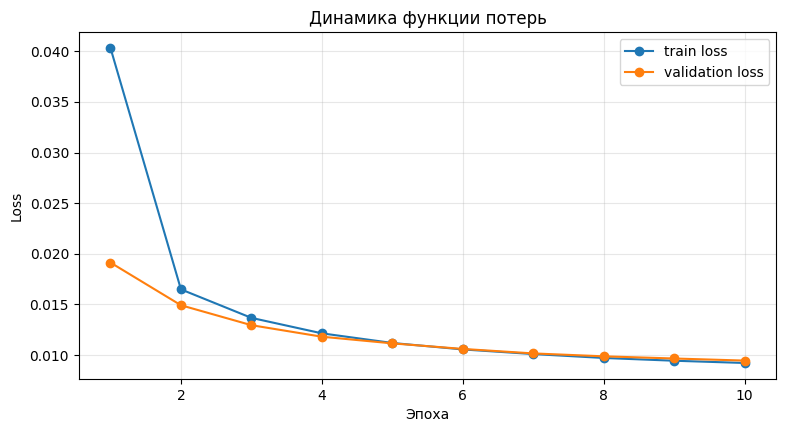

In [107]:
# Для каждой эпохи берём последнее доступное значение каждой метрики, пропуски игнорируются.
epoch_metrics = ae_metrics.groupby("epoch")[["train_loss", "val_loss"]].last()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1, epoch_metrics["train_loss"], marker="o", label="train loss"
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_loss"],
    marker="o",
    label="validation loss",
)
ax.set(xlabel="Эпоха", ylabel="Loss", title="Динамика функции потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Сравнение исходных и восстановленных изображений

Низкая ошибка реконструкции не гарантирует визуально идеальное восстановление. При ограниченной размерности кода decoder может терять мелкие детали, сглаживать границы или изменять толщину штрихов. Посмотрим на test-изображения, которые не участвовали в обучении.

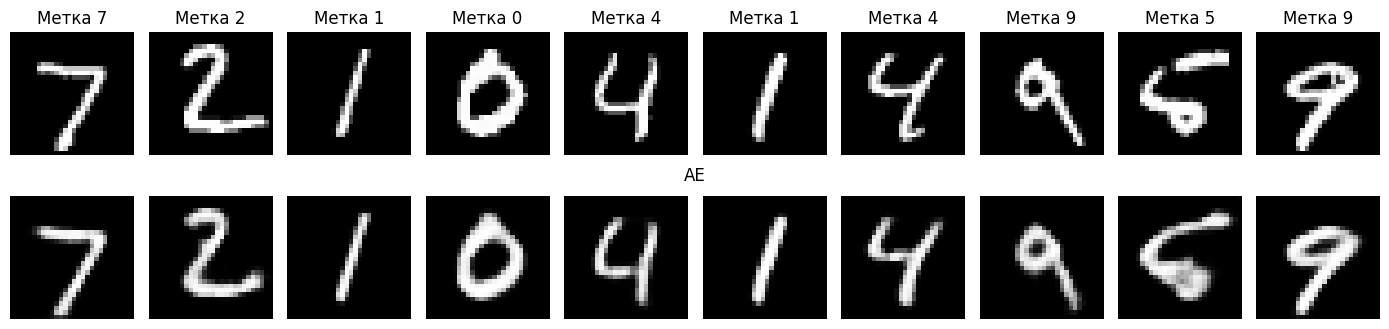

In [108]:
# Сравниваем исходные изображения MNIST с реконструкциями AE.
test_images, test_labels = next(iter(test_loader))
test_images = test_images[:10].to(device)

with torch.inference_mode():
    test_reconstructions = ae_best_model(test_images)

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))

for i in range(10):
    axes[0, i].imshow(test_images[i, 0].cpu(), cmap="gray")
    axes[0, i].set_title(f"Метка {test_labels[i].item()}")
    axes[1, i].imshow(test_reconstructions[i, 0].cpu(), cmap="gray")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

fig.text(
    0.5,
    0.49,
    "AE",
    ha="center",
    va="center",
    fontsize=12,
)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1)
plt.show()

**Задание.** Найдите изображения, которые AE восстанавливает хуже остальных. Какие детали теряются чаще: тонкие штрихи, наклон, замкнутые контуры или локальные особенности написания?

## Влияние размерности латентного вектора

Размерность `latent_dim` определяет, сколько чисел encoder может использовать для представления изображения. Маленький вектор сильнее ограничивает bottleneck, а большой позволяет сохранить больше деталей. Но увеличение размерности не гарантирует пропорционального улучшения: часть координат может оказаться малоиспользуемой.

Сравним несколько размерностей при одинаковых разбиениях и настройках обучения. Для выбора конфигурации используем validation, а test оставим для итоговой проверки.

In [13]:
# Обучаем AE с несколькими значениями latent_dim и сохраняем модели и метрики.
import pandas as pd


def train_autoencoder(latent_dim: int = 16):
    ae_lit = AELitModel(
        model=ConvAutoencoder,
        latent_dim=latent_dim,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=SEED,
    )

    ae_metrics = ae_lit.fit(
        train_loader=train_loader,
        validation_loader=validation_loader,
        epochs=MAX_EPOCHS,
        patience=MAX_EPOCHS,
    )

    ae_best_model = ae_lit.to(device).model.eval()

    return ae_metrics, ae_best_model


ae_models = {}
rows = []

latent_dimensions = [2, 3, 8, 16]

for latent_dim in latent_dimensions:
    metrics, model = train_autoencoder(latent_dim=latent_dim)

    ae_models[latent_dim] = model
    rows.append({"latent_dim": latent_dim, "best_val_mse": metrics["val_loss"].min()})


latent_results = pd.DataFrame(rows)
latent_results

,latent_dim,best_val_mse
0,2,0.045341
1,3,0.038367
2,8,0.020092
3,16,0.009425


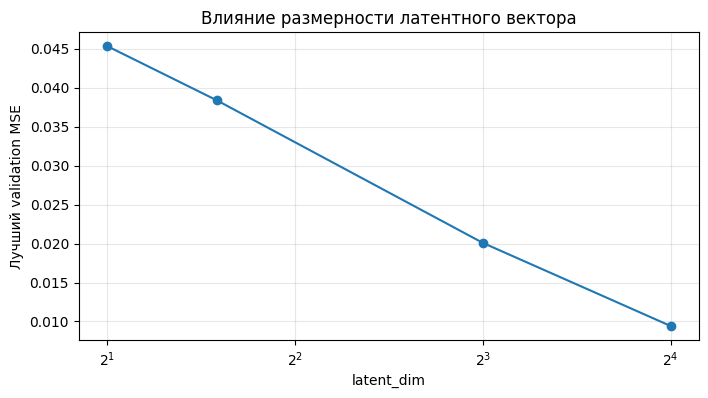

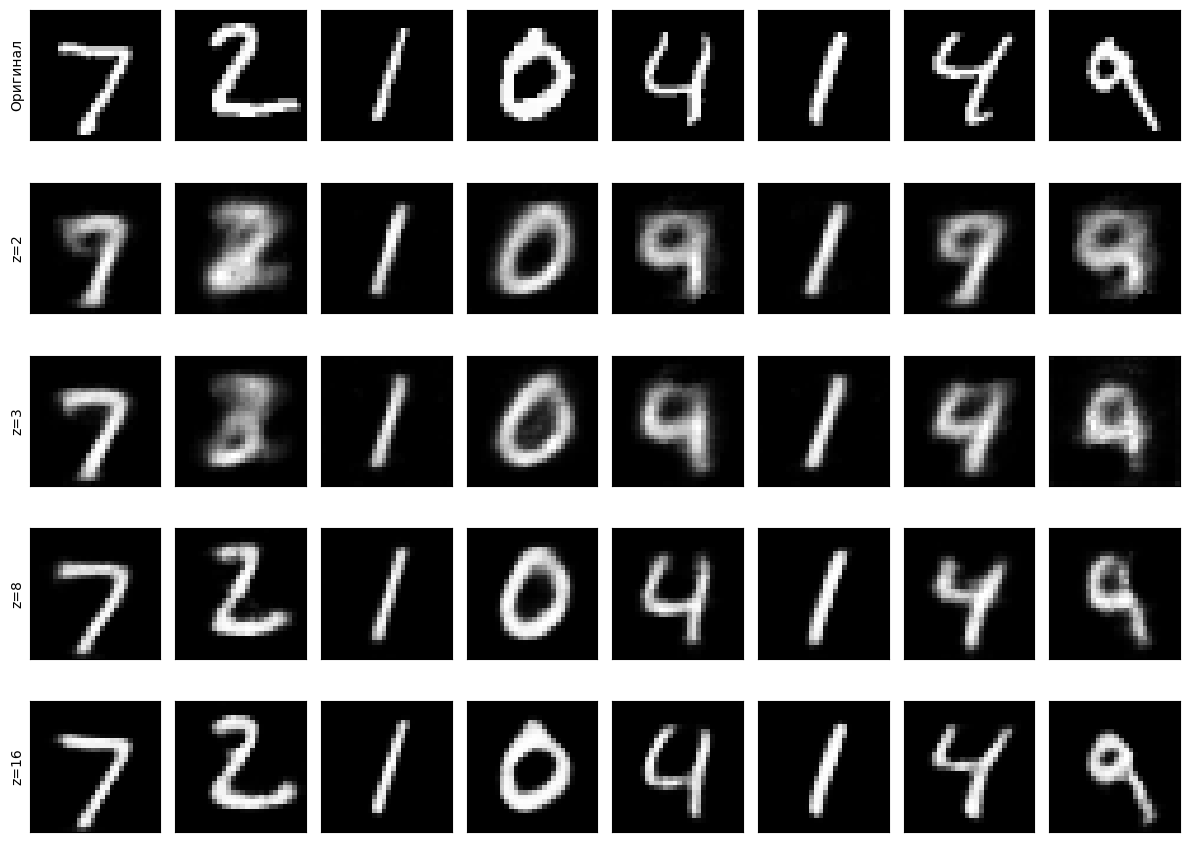

In [111]:
# Сопоставляем validation MSE и реконструкции для разных размерностей.
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(latent_results.latent_dim, latent_results.best_val_mse, marker="o")
ax.set(
    xlabel="latent_dim",
    ylabel="Лучший validation MSE",
    title="Влияние размерности латентного вектора",
)
ax.set_xscale("log", base=2)
ax.grid(alpha=0.3)
plt.show()

sample = test_images[:8]

fig, axes = plt.subplots(len(latent_dimensions) + 1, 8, figsize=(12, 9))

for j in range(8):
    axes[0, j].imshow(sample[j, 0].cpu(), cmap="gray")
    axes[0, j].set_xticks([])
    axes[0, j].set_yticks([])

axes[0, 0].set_ylabel("Оригинал")

for row, dim in enumerate(latent_dimensions, start=1):
    with torch.inference_mode():
        output = ae_models[dim].eval()(sample)

    for j in range(8):
        axes[row, j].imshow(output[j, 0].cpu(), cmap="gray")
        axes[row, j].set_xticks([])
        axes[row, j].set_yticks([])

    axes[row, 0].set_ylabel(f"z={dim}")

plt.tight_layout()
plt.show()

**Исследование.** Сопоставьте график MSE и галерею. Начиная с какой размерности визуальное улучшение становится небольшим? Есть ли примеры, где увеличение `latent_dim` почти не меняет результат? Зафиксируйте наблюдения своего запуска.

## Визуализация латентного пространства AE

Для `latent_dim=2` можно напрямую показать коды на плоскости. Для `latent_dim=3` построим интерактивный scatter plot с Plotly. Метки MNIST используются только для раскраски точек - сеть не обучалась на этих метках.

Если размерность больше трёх, для двумерной визуализации можно применить PCA.

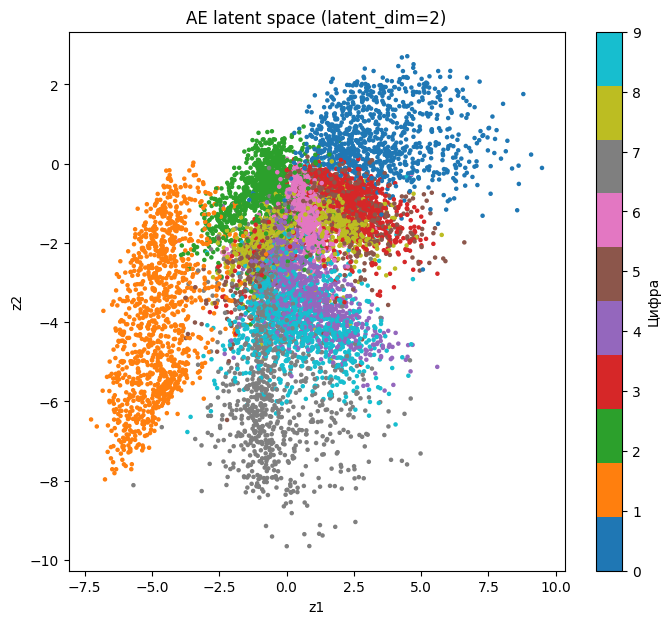

In [14]:
# Собираем латентные коды и метки, не используя метки внутри encoder.
def collect_latent_codes(model: ConvAutoencoder, loader: DataLoader[TensorPair]):
    model.eval()
    codes, labels_all = [], []
    with torch.inference_mode():
        for batch_images, batch_labels in loader:
            codes.append(model.encode(batch_images.to(device)).cpu().numpy())
            labels_all.append(batch_labels.cpu().numpy())
    return np.concatenate(codes), np.concatenate(labels_all)


codes_2d, labels_2d = collect_latent_codes(ae_models[2], test_loader)
fig, ax = plt.subplots(figsize=(8, 7))

sc = ax.scatter(codes_2d[:, 0], codes_2d[:, 1], c=labels_2d, cmap="tab10", s=5)

ax.set(xlabel="z1", ylabel="z2", title="AE latent space (latent_dim=2)")
fig.colorbar(sc, ax=ax, ticks=range(10), label="Цифра")
plt.show()

In [15]:
# Пространственное уменьшение облака точек.


def voxel_downsample(
    points: np.ndarray,
    labels: np.ndarray = None,
    target_points: int = 10_000,
    max_iter: int = 25,
):
    # Удаляем точки с некорректными координатами и синхронно фильтруем метки.
    valid = np.isfinite(points).all(axis=1)
    points = points[valid]

    if labels is not None:
        labels = labels[valid]

    # Если облако уже достаточно маленькое, возвращаем его без уменьшения.
    if len(points) <= target_points:
        if labels is None:
            return points.astype(np.float32), np.ones(len(points), dtype=int)
        return (
            points.astype(np.float32),
            labels,
            np.ones(len(points), dtype=int),
        )

    # Определяем границы облака и начальный диапазон поиска размера вокселя.
    p_min = points.min(axis=0)
    p_max = points.max(axis=0)

    low = 0.0
    high = np.linalg.norm(p_max - p_min)

    best = None

    # Бинарным поиском подбираем размер вокселя, обеспечивающий нужное число точек.
    for _ in range(max_iter):
        voxel_size = (low + high) / 2

        if voxel_size <= 0:
            break

        # Преобразуем координаты точек в целочисленные индексы вокселей.
        voxel_idx = np.floor((points - p_min) / voxel_size).astype(np.int64)

        # Объединяем точки с одинаковыми индексами вокселей.
        _, inverse = np.unique(voxel_idx, axis=0, return_inverse=True)

        n_voxels = inverse.max() + 1

        # Увеличиваем размер вокселя, если точек слишком много, иначе уменьшаем.
        if n_voxels > target_points:
            low = voxel_size
        else:
            high = voxel_size
            best = inverse.copy()

    # Если подходящий вариант не найден, выполняем разбиение с последним размером вокселя.
    if best is None:
        voxel_idx = np.floor((points - p_min) / high).astype(np.int64)

        _, best = np.unique(voxel_idx, axis=0, return_inverse=True)

    # Подсчитываем количество исходных точек, попавших в каждый воксель.
    n = best.max() + 1
    counts = np.bincount(best, minlength=n)

    # Заменяем точки каждого вокселя одной точкой с усреднёнными координатами.
    reduced = np.column_stack(
        [
            np.bincount(best, weights=points[:, i], minlength=n) / counts
            for i in range(3)
        ]
    )

    reduced = reduced.astype(np.float32)

    if labels is None:
        return reduced, counts

    # Назначаем каждому вокселю наиболее часто встречающуюся среди его точек метку.
    reduced_labels = np.empty(n, dtype=labels.dtype)

    for voxel in range(n):
        voxel_labels = labels[best == voxel]

        unique_labels, label_counts = np.unique(voxel_labels, return_counts=True)

        reduced_labels[voxel] = unique_labels[np.argmax(label_counts)]

    return reduced, reduced_labels, counts

In [18]:
# Строим интерактивный трёхмерный scatter plot для AE с latent_dim=3.
import plotly.graph_objects as go

codes_3d, labels_3d = collect_latent_codes(ae_models[3], test_loader)

reduced, reduced_labels, counts = voxel_downsample(
    codes_3d,
    labels_3d,
    target_points=5_000,
)

palette = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
    "#e377c2",
    "#7f7f7f",
    "#bcbd22",
    "#17becf",
]

colorscale = []
for i in range(10):
    colorscale.append([i / 10, palette[i]])
    colorscale.append([(i + 1) / 10, palette[i]])

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=reduced[:, 0],
            y=reduced[:, 1],
            z=reduced[:, 2],
            mode="markers",
            name="",
            marker=dict(
                size=2,
                color=reduced_labels,
                colorscale=colorscale,
                cmin=0,
                cmax=9,
                showscale=True,
                colorbar=dict(
                    title="Цифра",
                    tickmode="array",
                    tickvals=list(range(10)),
                    ticktext=[str(i) for i in range(10)],
                ),
            ),
        )
    ]
)

fig.update_layout(
    title=dict(
        text="AE latent space (latent_dim=3)",
        x=0.5,
        xanchor="center",
    ),
    scene=dict(
        aspectmode="data",
        xaxis_title="z1",
        yaxis_title="z2",
        zaxis_title="z3",
    ),
    width=1000,
    height=800,
    showlegend=True,
)

fig.show(renderer="notebook")

### PCA: проекция 16-мерных кодов в 2D

**Principal Component Analysis (PCA)** - метод линейного снижения размерности. Он находит ортогональные направления, вдоль которых данные имеют наибольшую дисперсию, и проецирует точки на первые главные компоненты.

PCA не переобучает AE и не меняет латентные коды. Он только строит двумерную проекцию уже полученных векторов.

Исходная размерность: 16
Доли дисперсии: [0.18509007 0.14484887]
Суммарная доля: 0.32993895


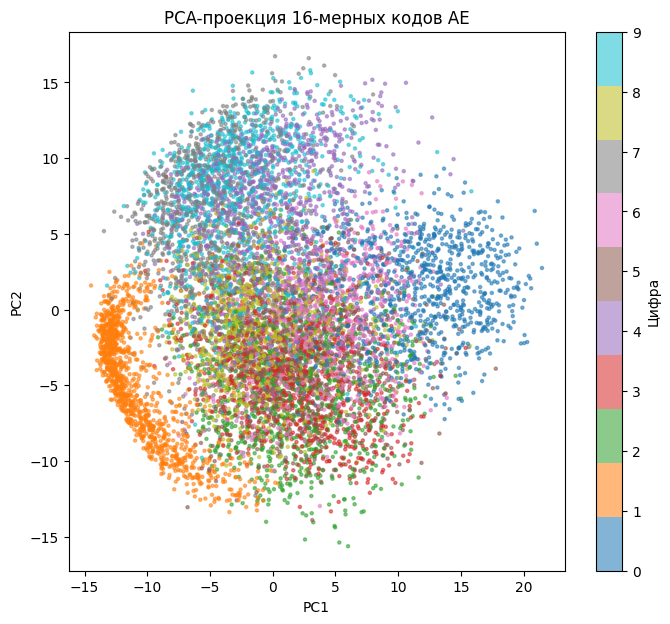

In [116]:
# Проецируем 16-мерные коды AE на две главные компоненты.
from sklearn.decomposition import PCA

codes_16d, labels_16d = collect_latent_codes(ae_models[16], test_loader)

pca = PCA(n_components=2, random_state=SEED)
codes_pca = pca.fit_transform(codes_16d)

print("Исходная размерность:", codes_16d.shape[1])
print("Доли дисперсии:", pca.explained_variance_ratio_)
print("Суммарная доля:", pca.explained_variance_ratio_.sum())

fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(
    codes_pca[:, 0], codes_pca[:, 1], c=labels_16d, cmap="tab10", s=5, alpha=0.55
)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA-проекция 16-мерных кодов AE")
fig.colorbar(sc, ax=ax, ticks=range(10), label="Цифра")

plt.show()

### Возможности и ограничения интерпретации латентного пространства

Визуализация помогает увидеть структуру данных, но не является полным объяснением работы сети (*explainability*).

- Если точки разных классов образуют области, это может означать, что encoder сохранил признаки, полезные для различения этих классов.
- Перекрытие классов не обязательно означает плохую реконструкцию: AE обучался восстанавливать изображения, а не разделять классы.
- Расстояние на двумерной PCA-проекции может не совпадать с расстоянием в исходном 16-мерном пространстве.
- Оси PCA не имеют заранее заданного смысла вроде «наклон цифры» или «толщина штриха».
- Цветовая разметка добавлена после обучения и не означает, что модель использовала классы.

Латентные координаты не становятся автоматически понятными человеку. Можно менять одну координату при фиксированных остальных и смотреть, как меняется реконструкция, но это показывает поведение модели, а не обязательно причинное объяснение.

**Задание:** сравните AE с `latent_dim=2` и PCA-проекцию AE с `latent_dim=16`. Какие выводы допустимы, а какие нельзя сделать по этим графикам?

## Почему обычный AE не гарантирует генерацию новых данных

AE учится кодировать реальные изображения и восстанавливать их. Он не обязан размещать коды в заранее заданной области или распределении. Коды могут занимать отдельные компактные области с промежутками между ними.

Если случайно выбрать точку из стандартного нормального распределения $z\sim\mathcal{N}(0,I)$, она может оказаться в области, которую decoder почти не видел во время обучения. Поэтому decoder не обязан сгенерировать осмысленную цифру.

Обычный AE хорошо решает задачу реконструкции, но не гарантирует удобное для генерации латентное пространство. Для этого используют VAE.

## Вариационный автокодировщик (VAE)

В VAE encoder возвращает не одну точку, а параметры вероятностного распределения:

$$
q_\phi(z|x)=\mathcal{N}(\mu(x),\operatorname{diag}(\sigma^2(x))).
$$

Encoder выдаёт два вектора:
- $\mu$ - среднее латентного распределения;
- `logvar` - логарифм дисперсии $\log\sigma^2$.

Логарифм удобен тем, что сеть может выдавать любое вещественное число, а дисперсия после экспоненты остаётся положительной.

VAE решает проблему генерации изображений с помощью AE, представляя каждый объект не одной точкой, а небольшим распределением в латентном пространстве. Вместо строго определённого кода модель получает область возможных латентных представлений.

В результате латентное пространство становится более непрерывным и упорядоченным: близкие точки соответствуют похожим объектам, а случайные точки из стандартного нормального распределения с большей вероятностью дают осмысленные результаты.

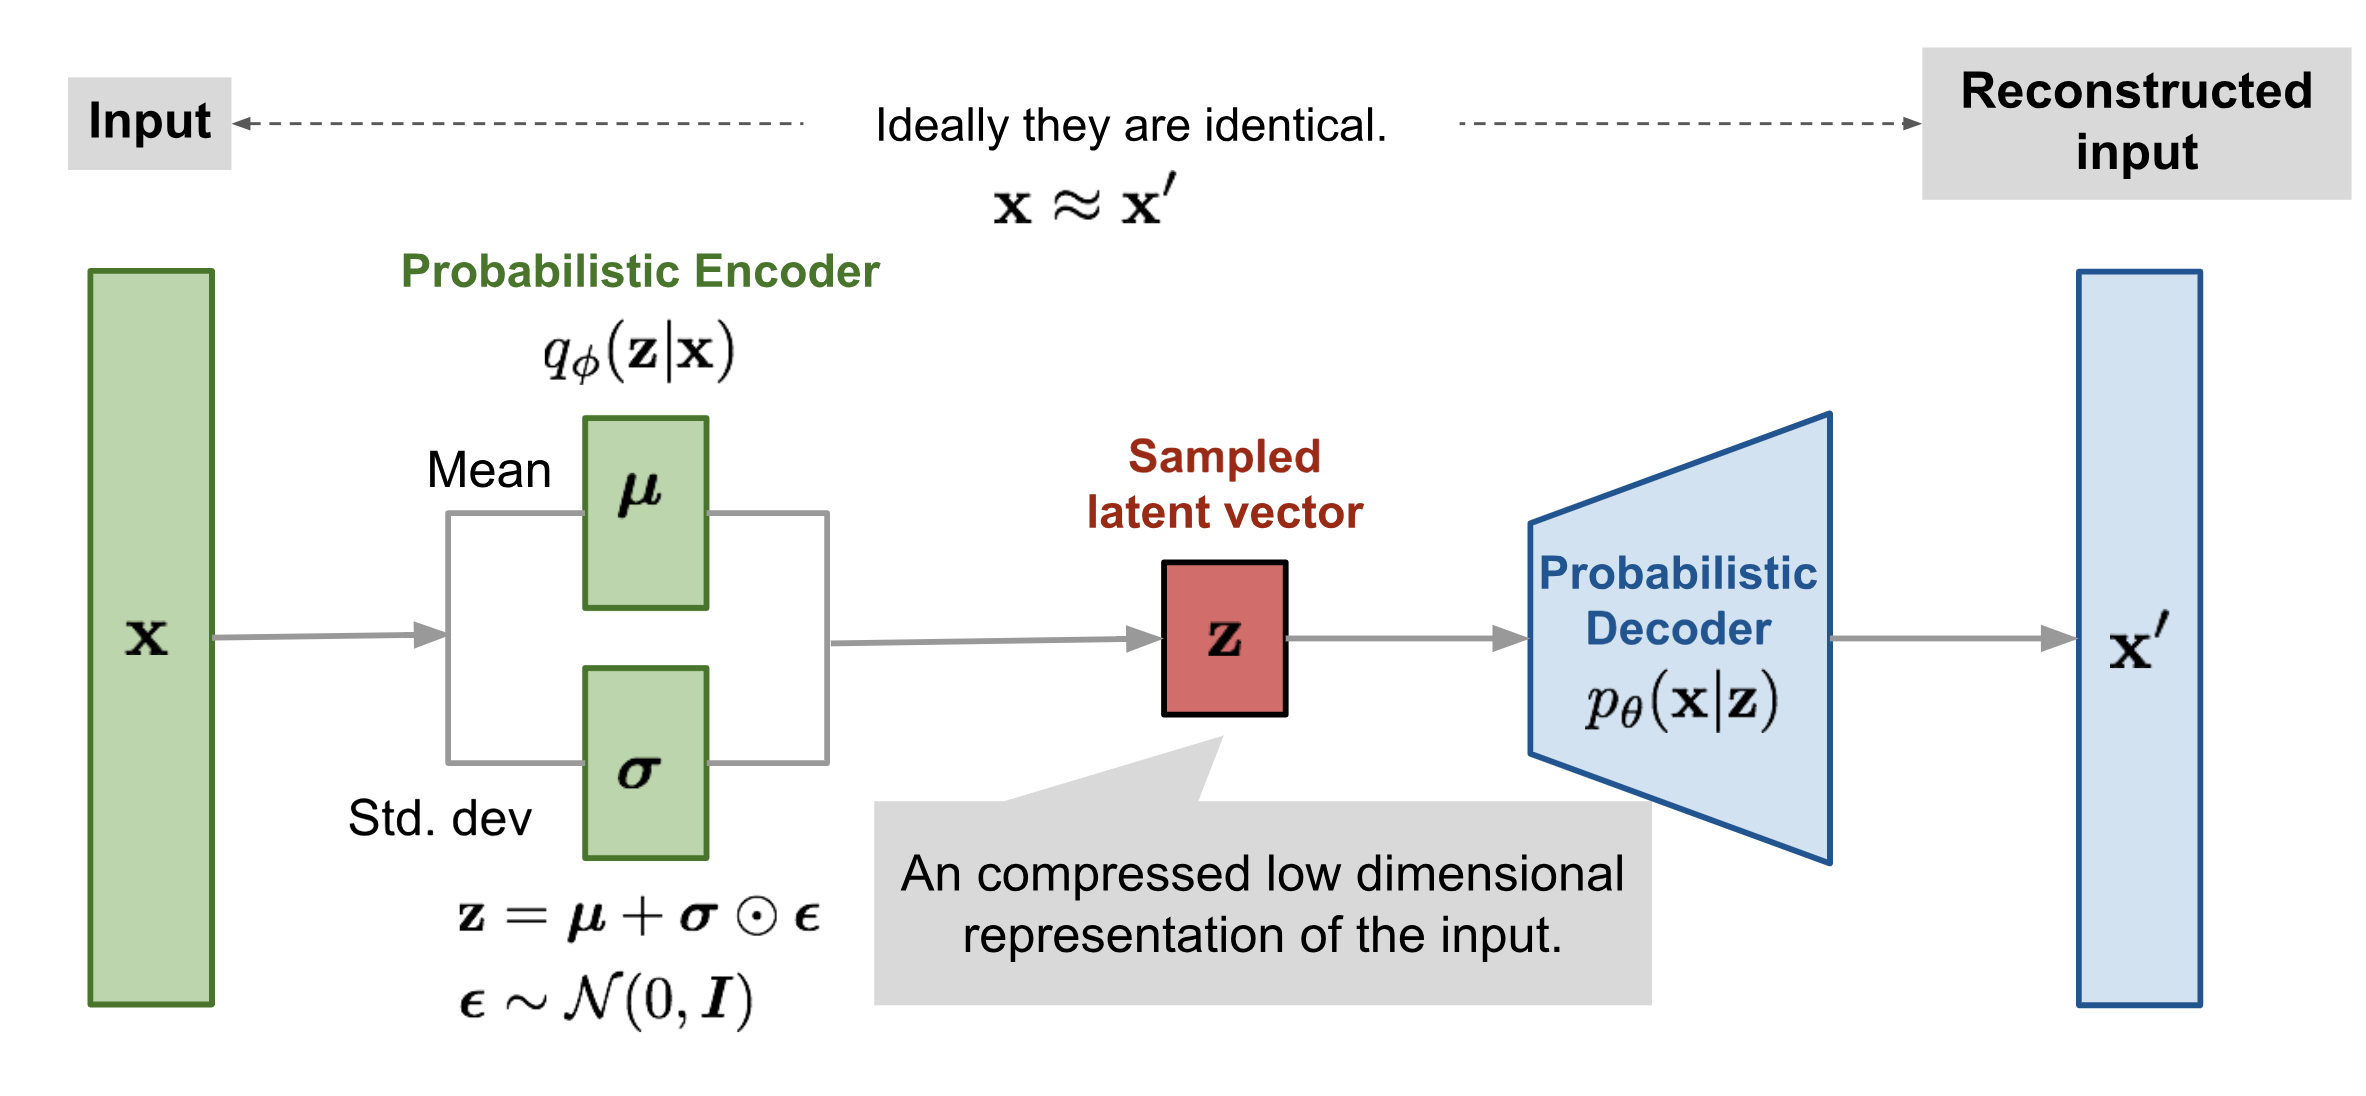

### Трюк репараметризации

Случайная выборка непосредственно из распределения затрудняет распространение градиента. Используем *reparameterization trick*:

$$
\epsilon\sim\mathcal{N}(0,I),\qquad
z=\mu+\sigma\odot\epsilon,\qquad
\sigma=\exp(0.5\cdot logvar).
$$

Случайность вынесена в независимую переменную $\epsilon$, а $z$ выражается через параметры encoder дифференцируемым образом. Поэтому градиент проходит к параметрам, вычисляющим среднее и дисперсию.

In [15]:
# Реализуем репараметризацию и проверяем формы тензоров.
def reparameterize(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
    """Сэмплирует z из диагонального нормального распределения."""
    std = torch.exp(0.5 * logvar)
    epsilon = torch.randn_like(std)
    return mu + std * epsilon


demo_mu = torch.zeros(4, 8, device=device)
demo_logvar = torch.zeros_like(demo_mu)
demo_z = reparameterize(demo_mu, demo_logvar)
print(
    "mu:",
    tuple(demo_mu.shape),
    "logvar:",
    tuple(demo_logvar.shape),
    "z:",
    tuple(demo_z.shape),
)

mu: (4, 8) logvar: (4, 8) z: (4, 8)


### KL-дивергенция и функция потерь VAE

Чтобы VAE не просто восстанавливал входные изображения, но и учился создавать новые, необходимо правильно организовать латентное пространство. Для этого в модели используется дополнительный член функции потерь - **KL-дивергенция (Kullback–Leibler divergence)**.

KL-дивергенция показывает, насколько распределение, которое encoder формирует для скрытых переменных $z$, отличается от заранее заданного нормального распределения $p(z)$.

Обычно в качестве априорного распределения используется стандартное нормальное распределение:

$$ p(z)=\mathcal{N}(0,I), $$

где $I$ - единичная матрица. Это означает, что значения латентных переменных должны быть распределены примерно вокруг нуля, а их дисперсия должна быть близка к единице.

Encoder для каждого входного изображения предсказывает два набора параметров:

- $\mu$ - среднее значение латентного распределения;
- $\sigma^2$ - дисперсию латентного распределения.

Таким образом, вместо одной фиксированной точки в латентном пространстве модель получает распределение, из которого можно случайным образом выбирать латентный вектор.

Для диагонального нормального распределения KL-дивергенция вычисляется по формуле:

$$ \mathcal{L}_{KL}= -\frac{1}{2}\sum_{j=1}^{d} \left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right). $$

Здесь $d$ - размерность латентного пространства, а суммирование выполняется по всем его координатам.


Если распределение encoder сильно отличается от стандартного нормального распределения, значение KL-дивергенции будет большим. Это означает, что модель недостаточно хорошо организует латентное пространство.

Если же распределения близки друг к другу, KL-дивергенция будет небольшой. В результате латентное пространство становится более упорядоченным: близкие точки могут соответствовать похожим изображениям, а случайные векторы, взятые из стандартного нормального распределения, с большей вероятностью будут давать осмысленные результаты при декодировании.

В PyTorch KL-дивергенция вычисляется следующим образом:

```python
kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1).mean()
```

### Итоговая функция потерь VAE

Общая функция потерь вариационного автокодировщика состоит из двух частей:

$$ \mathcal{L}_{VAE}= \mathcal{L}_{rec}+\beta\mathcal{L}_{KL}. $$

**1. Ошибка реконструкции (**$\mathcal{L}_{rec}$**).**

Показывает, насколько восстановленное изображение отличается от исходного. Например, при использовании MSE (среднеквадратичной ошибки) модель стремится сделать реконструкцию максимально похожей на входное изображение.

**2. KL-дивергенция (**$\mathcal{L}_{KL}$**).**

Отвечает за организацию латентного пространства и заставляет распределения, полученные encoder, быть похожими на стандартное нормальное распределение.

Коэффициент $\beta$ определяет, насколько сильно модель учитывает KL-дивергенцию при обучении.

- Если $\beta$ слишком большой, модель будет сильнее стремиться к нормальному распределению. Это может привести к потере деталей на восстановленных изображениях.
- Если $\beta$ слишком маленький, модель будет уделять больше внимания точности реконструкции, но латентное пространство может получиться менее упорядоченным. В результате генерация новых изображений может работать хуже.

### Особенность реализации в данной работе

KL-дивергенция сначала суммируется по всем координатам латентного пространства, а затем усредняется по объектам в батче. Дополнительно полученное значение нормируется на количество пикселей изображения.

Это сделано для того, чтобы привести масштаб KL-дивергенции к более сопоставимому уровню с ошибкой реконструкции, которая рассчитывается с использованием пиксельной MSE. Благодаря этому оба компонента функции потерь оказывают более контролируемое влияние на процесс обучения.

In [16]:
# Реализуем общую функцию потерь VAE: реконструкция плюс KL-регуляризация.
import torch.nn.functional as F


class VAELoss(nn.Module):
    def __init__(self, kld_weight: float, recon_weight=1.0):
        super().__init__()

        self.kld_weight = kld_weight
        self.recon_weight = recon_weight

    def kld_loss(self, mu, logvar):
        var = torch.exp(logvar)
        kl_loss = torch.mean(-0.5 * torch.sum(logvar - var - mu**2 + 1, dim=1), dim=0)
        return kl_loss

    def forward(self, y_pred, y_true, mu, logvar):
        loss = self.recon_weight * F.mse_loss(
            y_pred, y_true
        ) + self.kld_weight * self.kld_loss(mu, logvar)

        return loss


loss = VAELoss(1).to(device)
zero = torch.zeros(16, 4, device=device)
ones = torch.ones(16, 4, device=device)

print("KL для N(0, I):", loss.kld_loss(zero, torch.log(ones)))

KL для N(0, I): tensor(0., device='cuda:0')


## Реализация свёрточного VAE

Архитектура похожа на AE, но encoder формирует два вектора: `mu` и `logvar`. Из них с помощью репараметризации получается `z`, который декодируется в изображение. Сохраняем те же размеры карт признаков, что и у AE. 

In [ ]:
# Реализуем свёрточный VAE с отдельными головами для mu и logvar.


class ConvVAE(nn.Module):
    def __init__(self, latent_dim: int = 16) -> None:
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(1),
        )

        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        # Используем вспомогательный модуль для корректного отображения с помощью visualtorch.
        self.code = Code()

        self.decoder_conv = nn.Sequential(
            nn.Linear(latent_dim, 64 * 7 * 7),
            nn.Unflatten(1, unflattened_size=(64, 7, 7)),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x: torch.Tensor) -> TensorPair:
        features = self.encoder_conv(x)
        return self.fc_mu(features), self.fc_logvar(features)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder_conv(z)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, ...]:
        mu, logvar = self.encode(x)

        code = reparameterize(mu, logvar)
        code = self.code(code)

        return self.decode(code), mu, logvar


vae_model = ConvVAE(16).to("cuda")
example = torch.randn(4, 1, 28, 28, device="cuda")
with torch.inference_mode():
    rec, mu, logvar = vae_model(example)

print(
    "Реконструкция:",
    tuple(rec.shape),
    "mu:",
    tuple(mu.shape),
    "logvar:",
    tuple(logvar.shape),
)

Реконструкция: (4, 1, 28, 28) mu: (4, 16) logvar: (4, 16)


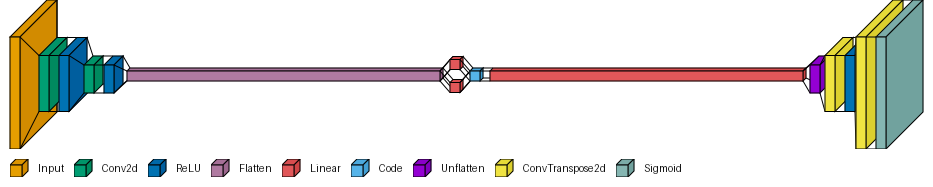

In [18]:
img = visualtorch.render(
    vae_model.cpu(),
    input_shape=(4, 1, 28, 28),
    style="flow",
    legend=True,
    scale_xy=4,
    color_map=color_map,
)

img

### Обучение VAE

Унаследуемся от `AELitModel` и переопределим loss-функцию и логику прямого прохода.

In [19]:
# Переопределим criterion и _shared_step.


class VAELitModel(AELitModel):
    def __init__(
        self,
        model: type[nn.Module],
        seed: int | None = None,
        lr: float = 1e-3,
        weight_decay: float = 1e-4,
        kld_weight: float = 0.005,
        recon_weight: float = 1.0,
        **kwargs,
    ) -> None:
        super().__init__(
            model=model,
            seed=seed,
            lr=lr,
            weight_decay=weight_decay,
            **kwargs,
        )

        self.criterion = VAELoss(kld_weight=kld_weight, recon_weight=recon_weight)

    def _shared_step(self, batch: TensorPair) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        features, _ = batch

        reconstructed, mu, logvar = self(features)

        loss = self.criterion(
            reconstructed,
            features,
            mu,
            logvar,
        )

        return loss

In [30]:
# Создаём вариационный автокодировщик и обучаем его с помощью VAELitModel.
vae_lit = VAELitModel(
    model=ConvVAE,
    latent_dim=16,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

vae_metrics = vae_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

vae_best_model = vae_lit.to(device).model.eval()

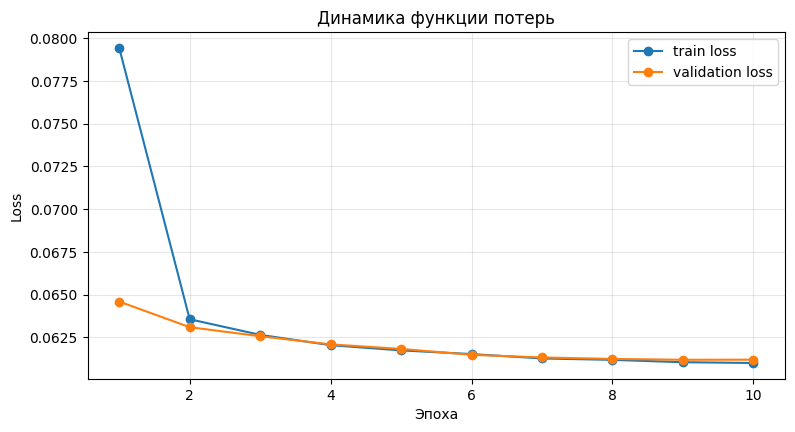

In [31]:
# Для каждой эпохи берём последнее доступное значение каждой метрики, пропуски игнорируются.
epoch_metrics = vae_metrics.groupby("epoch")[["train_loss", "val_loss"]].last()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1, epoch_metrics["train_loss"], marker="o", label="train loss"
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_loss"],
    marker="o",
    label="validation loss",
)
ax.set(xlabel="Эпоха", ylabel="Loss", title="Динамика функции потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Сравнение AE и VAE

Сравним модели с одинаковой размерностью латентного вектора. У AE код детерминированный, у VAE реконструкция зависит от случайного семплирования. Поэтому два прохода одного изображения через VAE могут дать немного разные результаты. VAE оптимизирует не только MSE, но и регуляризацию распределения.

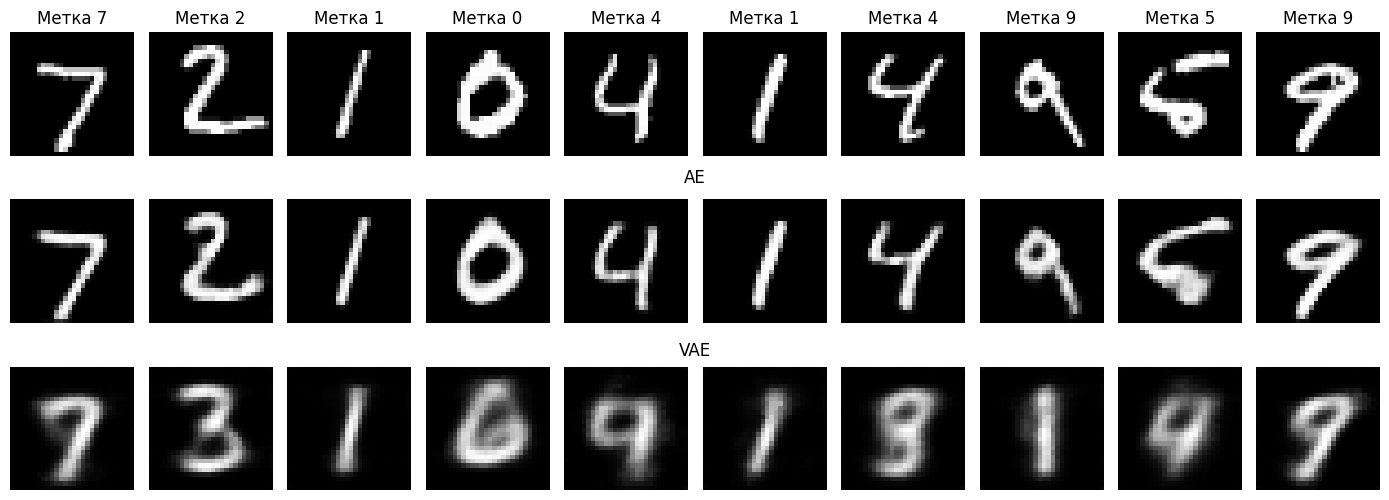

In [ ]:
# Сопоставляем исходные изображения и реконструкции AE/VAE.
test_images, test_labels = next(iter(test_loader))
test_images = test_images[:10].to(device)

with torch.inference_mode():
    ae_recon = ae_best_model(test_images)
    vae_recon, *_ = vae_best_model(test_images)

fig, axes = plt.subplots(3, 10, figsize=(14, 5.25))

for i in range(10):
    axes[0, i].imshow(test_images[i, 0].cpu(), cmap="gray")
    axes[0, i].set_title(f"Метка {test_labels[i].item()}")
    axes[1, i].imshow(ae_recon[i, 0].cpu(), cmap="gray")
    axes[2, i].imshow(vae_recon[i, 0].cpu(), cmap="gray")

    axes[0, i].axis("off")
    axes[1, i].axis("off")
    axes[2, i].axis("off")

fig.text(
    0.5,
    0.65,
    "AE",
    ha="center",
    va="center",
    fontsize=12,
)

fig.text(
    0.5,
    0.32,
    "VAE",
    ha="center",
    va="center",
    fontsize=12,
)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1)
plt.show()

**Небольшое исследование.** Почему VAE может хуже восстанавливать изображения? Как это связано с ненулевым весом KL-дивергенции в функции потерь?

## Плотность точек в латентных пространствах AE и VAE

Сравним двумерные коды AE с VAE. Для VAE можно отобразить средние `mu` и случайные сэмплы `z`. 

In [34]:
# Создаём вариационный автокодировщик и обучаем его с помощью VAELitModel.
vae_2d_lit = VAELitModel(
    model=ConvVAE,
    latent_dim=2,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

vae_2d_metrics = vae_2d_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

vae_2d_best_model = vae_2d_lit.to(device).model.eval()

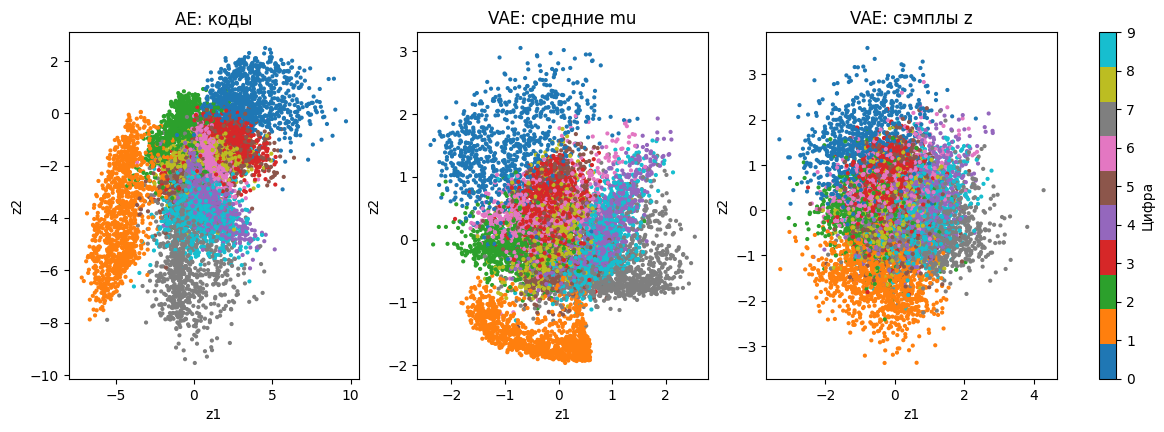

In [35]:
# Сравниваем AE-коды, средние VAE и случайные сэмплы z на двумерных графиках.
mu_parts, z_parts, label_parts = [], [], []

with torch.inference_mode():
    for x, y in test_loader:
        mu, logvar = vae_2d_best_model.encode(x)
        mu_parts.append(mu.cpu().numpy())
        z_parts.append(reparameterize(mu, logvar).cpu().numpy())
        label_parts.append(y.cpu().numpy())

vae_mu = np.concatenate(mu_parts)
vae_z = np.concatenate(z_parts)
vae_labels = np.concatenate(label_parts)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), gridspec_kw={"right": 0.88})

for ax, points, title in [
    (axes[0], codes_2d, "AE: коды"),
    (axes[1], vae_mu, "VAE: средние mu"),
    (axes[2], vae_z, "VAE: сэмплы z"),
]:
    sc = ax.scatter(points[:, 0], points[:, 1], c=vae_labels, cmap="tab10", s=4)
    ax.set(title=title, xlabel="z1", ylabel="z2")

cbar = fig.colorbar(sc, ax=axes, location="right", fraction=0.025, pad=0.04)
cbar.set_label("Цифра")

plt.show()

**Задание.** Сравните распределения. Насколько плотно точки VAE заполняют пространство? Видны ли промежутки между группами? Почему визуализация `mu` отличается от случайных `z`? Почему точки VAE имеют меньший разброс?

## Supervised VAE: учёт информации о классах

VAE ничего не знает о классах объектов. Поэтому он не обязан размещать объекты одного класса рядом, а объекты разных классов - далеко друг от друга. Он может сформировать пересекающиеся группы, поменять их местами или расположить их в латентном пространстве совершенно не так, как ожидается при визуализации по классам.

Если нам важно, чтобы латентное пространство учитывало классы, можно использовать **Supervised VAE** - вариационный автокодировщик с учётом меток классов.

Один из вариантов реализации - добавить к стандартной функции потерь дополнительную классификационную составляющую:

$$
\mathcal{L} =
\mathcal{L}_{rec}
+ \beta \mathcal{L}_{KL}
+ \lambda \mathcal{L}_{class},
$$

где:
- $\mathcal{L}_{rec}$ - ошибка восстановления исходных данных;
- $\mathcal{L}_{KL}$ - расхождение между апостериорным и априорным распределениями;
- $\mathcal{L}_{class}$ - ошибка классификации объектов по латентному представлению.

Классификационная составляющая заставляет латентное представление сохранять информацию, необходимую для определения класса. В результате объекты одного класса могут образовывать более выраженные группы, а разные классы - лучше разделяться.

**Важно:** Supervised VAE не гарантирует идеального разделения классов. Результат зависит от архитектуры, функции потерь и весов её составляющих. Кроме того, существуют разные способы включения меток в вариационный автокодировщик.

## Интерполяция между латентными представлениями

Для двух кодов $z_a$ и $z_b$ линейная интерполяция:

$$
z(t)=(1-t)z_a+t z_b,\qquad t\in[0,1].
$$

При $t=0$ получаем первый код, при $t=1$ - второй. Промежуточные точки decoder преобразует в изображения. У AE переход может проходить через области, где модель почти не видела латентных кодов. Регуляризация VAE обычно делает пространство более удобным для интерполяции, но не гарантирует осмысленность каждой промежуточной точки.

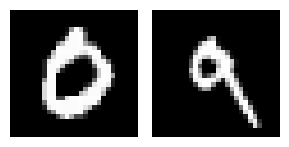

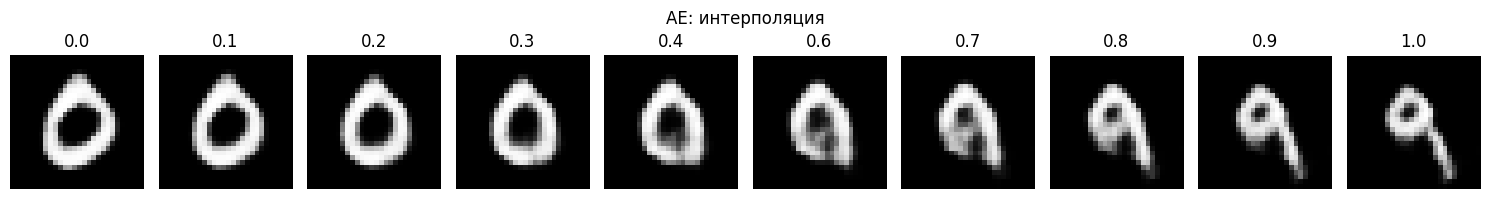

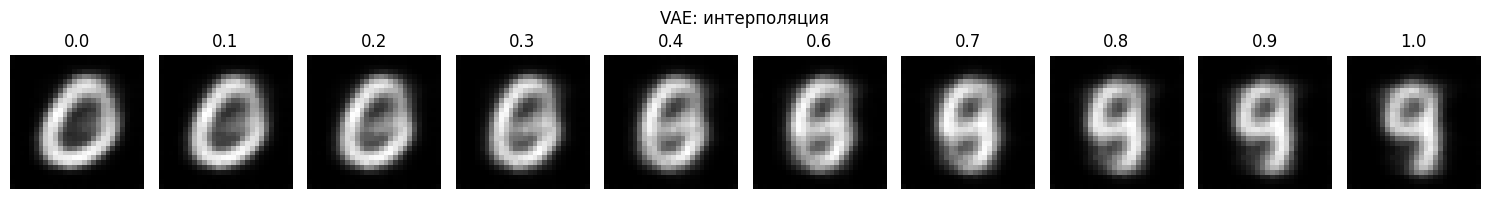

In [222]:
# Строим ряд изображений между кодами двух разных цифр.


def show_interpolation(
    model: nn.Module,
    z_start: torch.Tensor,
    z_end: torch.Tensor,
    steps: int = 10,
    title="Интерполяция",
):
    model.eval()
    values = torch.linspace(0, 1, steps, device=device)
    path = torch.stack([(1 - t) * z_start + t * z_end for t in values])

    with torch.inference_mode():
        generated = model.decode(path).cpu()

    fig, axes = plt.subplots(1, steps, figsize=(1.5 * steps, 2))
    for i, ax in enumerate(axes):
        ax.imshow(generated[i, 0], cmap="gray")
        ax.set_title(f"{values[i].item():.1f}")
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


chosen = {}
for i, (_, label) in enumerate(test_dataset):
    chosen.setdefault(int(label), i)
    if len(chosen) == 10:
        break

idx_a, idx_b = chosen[0], chosen[9]

image_a = collator([test_dataset[idx_a]])[0]
image_b = collator([test_dataset[idx_b]])[0]

with torch.inference_mode():
    za1, za2 = ae_best_model.encode(image_a), ae_best_model.encode(image_b)
    zv1, *_ = vae_best_model.encode(image_a)
    zv2, *_ = vae_best_model.encode(image_b)

fig, axes = plt.subplots(1, 2, figsize=(3, 2))
axes[0].imshow(test_dataset[idx_a][0], cmap="gray")
axes[0].axis("off")
axes[1].imshow(test_dataset[idx_b][0], cmap="gray")
axes[1].axis("off")
plt.tight_layout()
plt.show()

show_interpolation(ae_best_model, za1[0], za2[0], title="AE: интерполяция")
show_interpolation(vae_best_model, zv1[0], zv2[0], title="VAE: интерполяция")

**Исследование.** Выберите другие пары цифр и сравните переходы. Изменяется ли форма постепенно? Есть ли промежуточные изображения, которые трудно отнести к конкретному классу?

## Генерация изображений из VAE

После обучения VAE можно сэмплировать новый латентный вектор из априорного распределения $z\sim\mathcal{N}(0,I)$, а затем передать его в decoder. Это ключевое отличие от обычного AE: VAE обучает encoder согласовывать латентные распределения с априорным. Качество зависит от обучения, размерности, коэффициента KL и архитектуры; не каждая случайная точка обязана дать идеальную цифру.

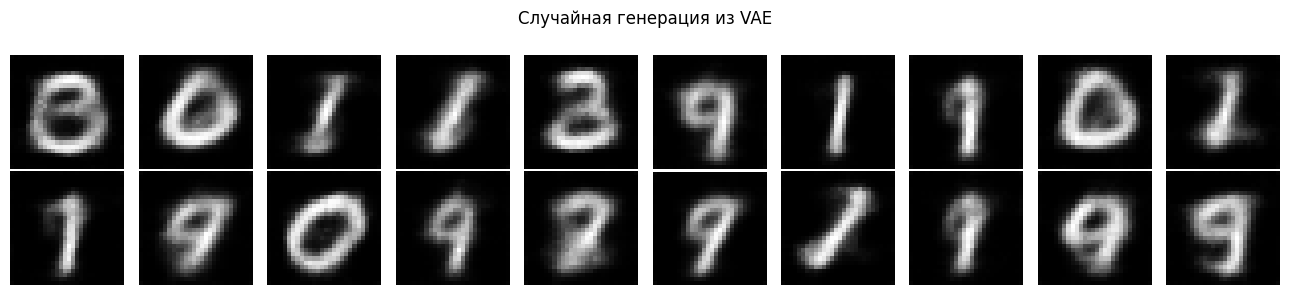

In [54]:
# Генерируем изображения из стандартного нормального распределения.
num_samples = 20

generator = torch.Generator().manual_seed(SEED)
random_codes = torch.randn(num_samples, 16, generator=generator).to(device)

with torch.inference_mode():
    generated = vae_best_model.decode(random_codes).cpu()

fig, axes = plt.subplots(2, 10, figsize=(13, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i, 0], cmap="gray")
    ax.axis("off")

plt.suptitle("Случайная генерация из VAE")
plt.tight_layout()
plt.show()

# Дополнительная часть. Условный вариационный автокодировщик (CVAE)

## Условная генерация

Обычный VAE генерирует изображения без явного указания желаемого класса. При семплировании из стандартного нормального распределения мы не можем напрямую потребовать конкретную цифру.

**CVAE** получает дополнительное условие $y$ - в нашей задаче метку цифры. Encoder получает изображение и метку, decoder - латентный код и ту же метку:

$$
q_\phi(z|x,y),\qquad p_\theta(x|z,y).
$$

При генерации задаётся класс изображения $y$, случайно выбирается $z$ и передаётся оба значения decoder. Это позволяет управлять классом генерируемой цифры.

## `nn.Embedding` для представления метки класса

Метка MNIST - целое число от 0 до 9. Однако эти числа обозначают категории, а не измеряемые величины. Например, цифра 8 не является «в два раза больше» цифры 4, поэтому использовать числовое значение метки как обычный признак некорректно.

Для представления таких категориальных данных используется слой `nn.Embedding`. Он хранит обучаемую таблицу векторов, в которой каждому классу соответствует отдельный вектор фиксированной размерности. При передаче метки класса слой извлекает соответствующий вектор из этой таблицы.

В отличие от обычного числового представления, embedding позволяет модели самостоятельно научиться формировать представления классов, учитывая особенности решаемой задачи. В процессе обучения значения векторов изменяются вместе с остальными параметрами модели.

В условии MNIST используется таблица из 10 векторов, по одному для каждой цифры от 0 до 9. Размерность каждого вектора определяет, сколько дополнительных признаков будет использовать модель для представления метки класса.

Полученный embedding объединяется с признаками изображения на входе encoder, а также с латентным кодом на входе decoder. Таким образом, информация о классе становится доступна обеим частям модели: encoder учитывает заданную категорию при формировании латентного представления, а decoder использует её при генерации изображения.


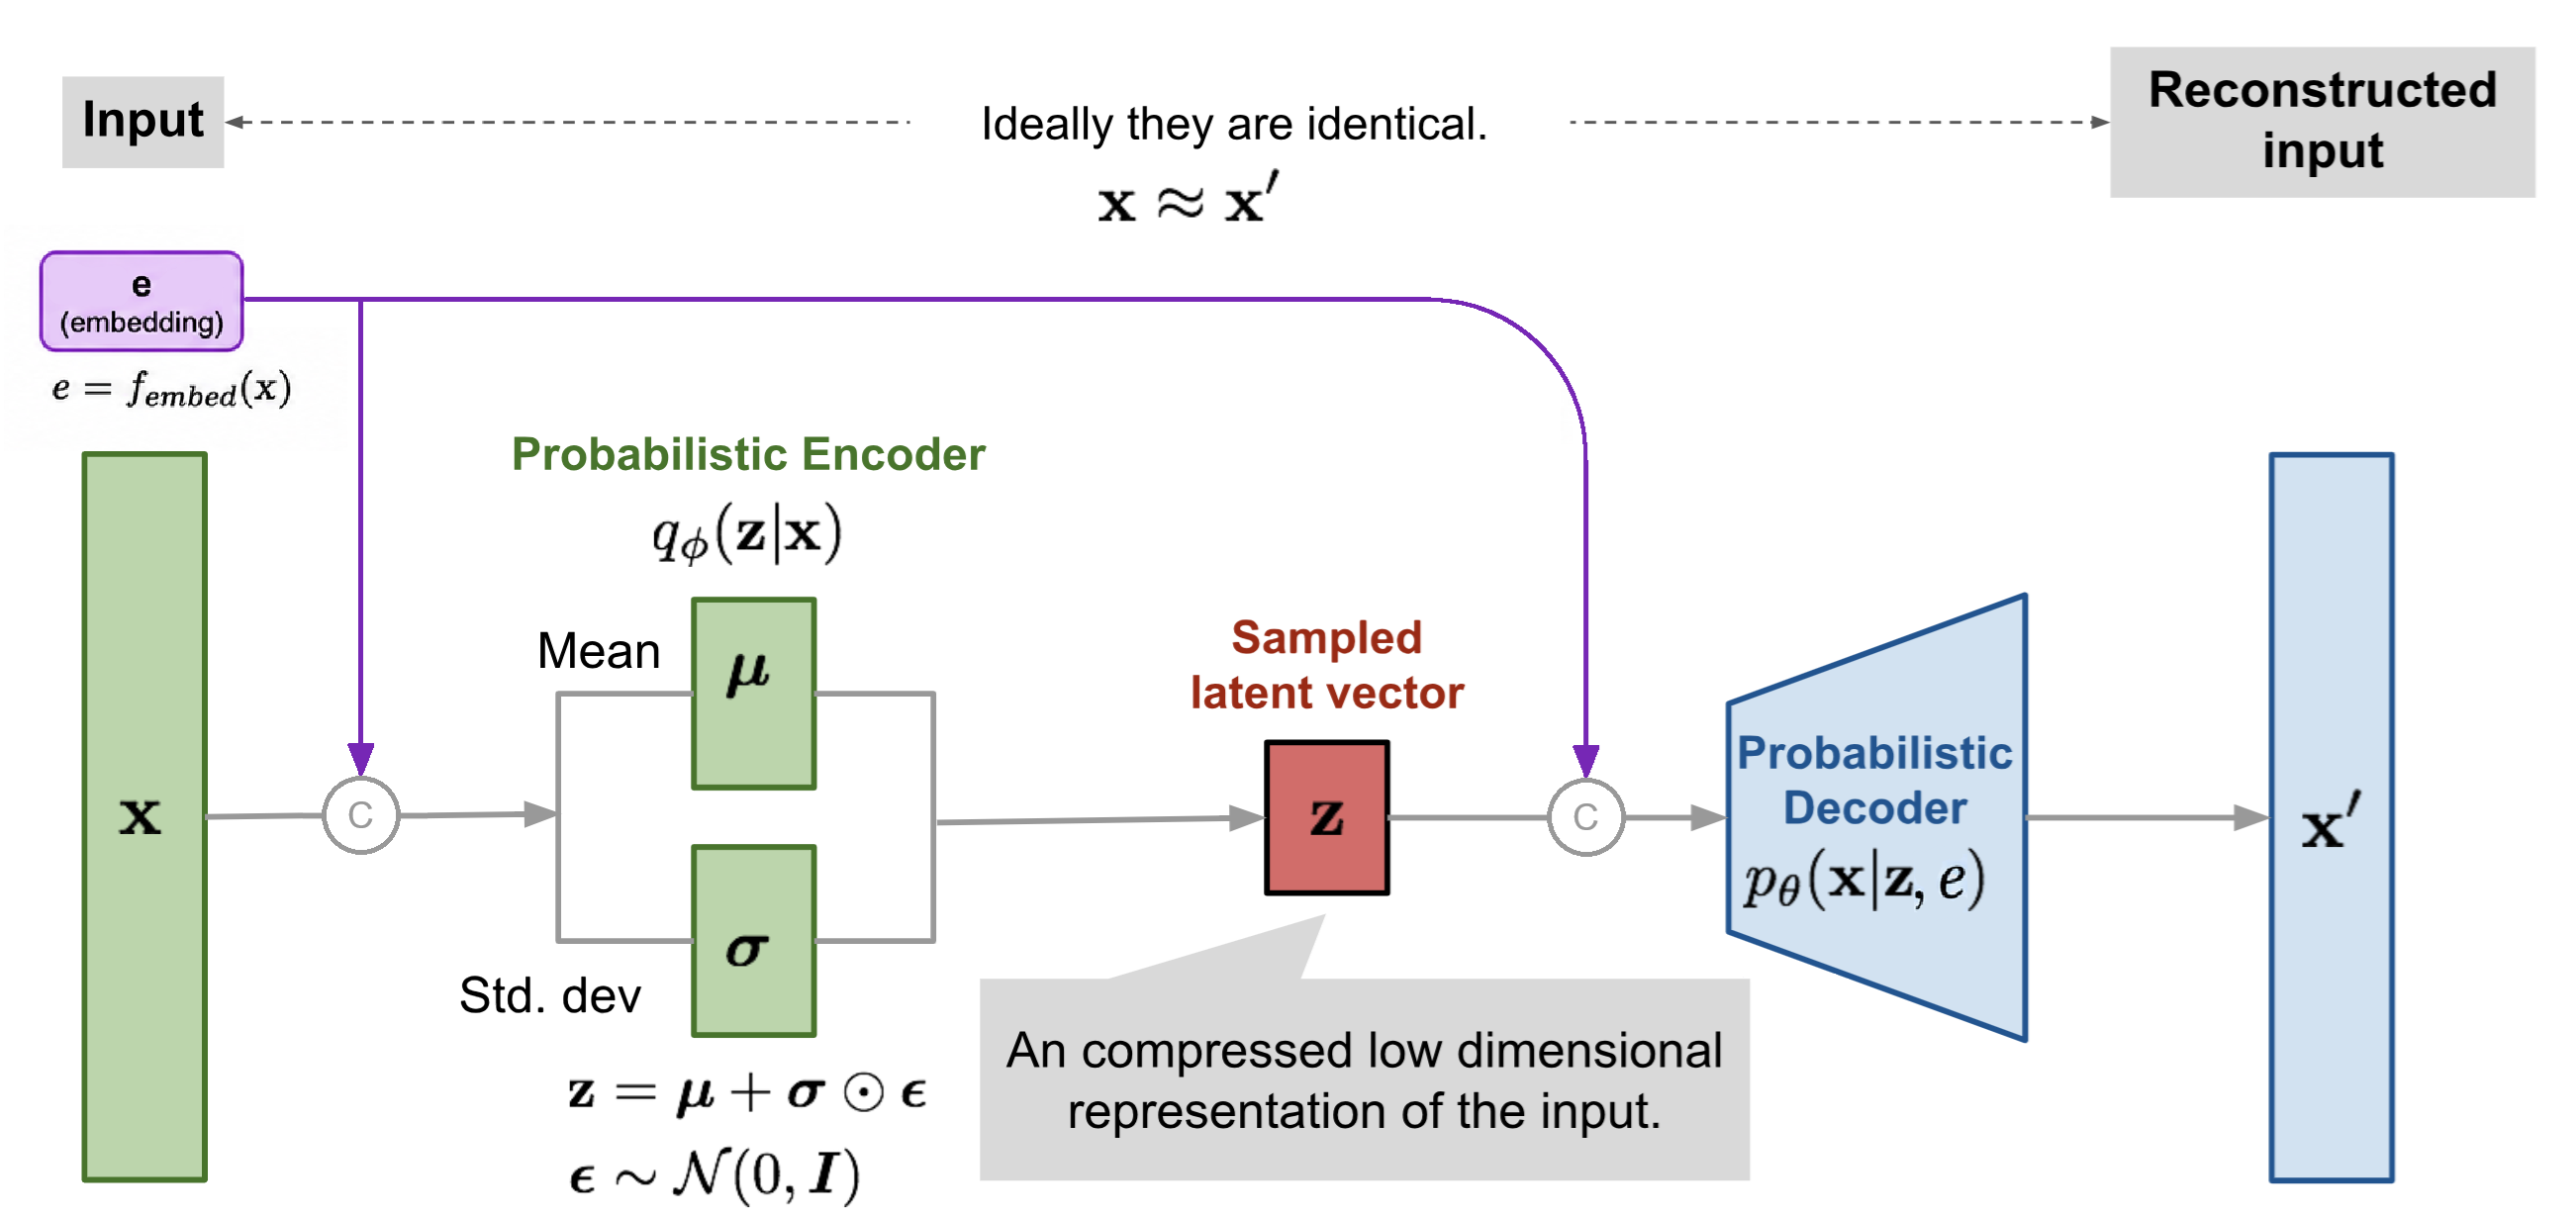

## Реализация свёрточного CVAE

Encoder получает изображение и embedding метки. После свёрточных слоёв объединяет признаки с embedding и вычисляет `mu` и `logvar`. Decoder объединяет `z` с embedding той же метки.

**Задание:** проследите за размерностями конкатенации. Метка является условием генерации, а не целью для классификатора.

In [92]:
# Реализуем CVAE с embedding метки и условием на encoder/decoder.


class ConvCVAE(nn.Module):
    def __init__(
        self, latent_dim: int = 16, num_classes: int = 10, label_dim: int = 16
    ):
        super().__init__()
        self.latent_dim = latent_dim

        self.label_embedding = nn.Embedding(num_classes, label_dim)

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(1),
        )

        self.fc_mu = nn.Linear(64 * 7 * 7 + label_dim, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7 + label_dim, latent_dim)

        # Используем вспомогательные модули для корректного отображения с помощью visualtorch.
        self.concat = Concatenate(dim=1)
        self.code = Code()

        self.decoder_conv = nn.Sequential(
            nn.Linear(latent_dim + label_dim, 64 * 7 * 7),
            nn.Unflatten(1, unflattened_size=(64, 7, 7)),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x: torch.Tensor, labels: torch.Tensor) -> TensorPair:
        features = self.encoder_conv(x)

        label_features = self.label_embedding(labels)
        joint = self.concat([features, label_features])

        return self.fc_mu(joint), self.fc_logvar(joint)

    def decode(self, z: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        label_features = self.label_embedding(labels)
        joint = self.concat([z, label_features])

        return self.decoder_conv(joint)

    def forward(
        self, x: torch.Tensor, labels: torch.Tensor
    ) -> tuple[torch.Tensor, ...]:
        mu, logvar = self.encode(x, labels)

        code = reparameterize(mu, logvar)
        code = self.code(code)

        return self.decode(code, labels), mu, logvar


cvae_model = ConvCVAE().to(device)
demo_labels = torch.tensor([0, 1, 2, 3], device=device)

with torch.inference_mode():
    cvae_rec, cvae_mu, cvae_logvar = cvae_model(example, demo_labels)

print(
    "Реконструкция:",
    tuple(cvae_rec.shape),
    "mu:",
    tuple(cvae_mu.shape),
    "logvar:",
    tuple(cvae_logvar.shape),
)

Реконструкция: (4, 1, 28, 28) mu: (4, 16) logvar: (4, 16)


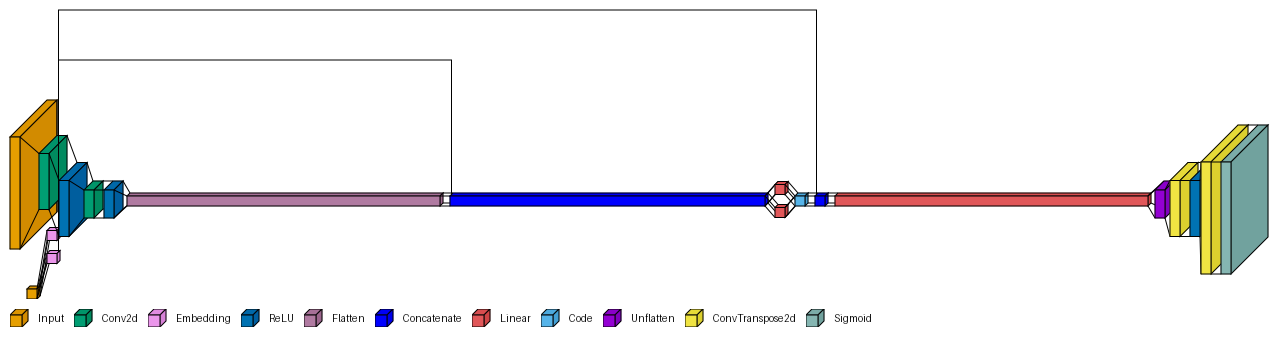

In [93]:
img = visualtorch.render(
    cvae_model.cpu(),
    input_shape=((4, 1, 28, 28), (4,)),
    input_dtype=(torch.float32, torch.long),
    style="flow",
    legend=True,
    scale_xy=4,
    force_detour=True,
    color_map=color_map,
)

img

## Обучение CVAE

Функция потерь CVAE имеет ту же структуру, что и у VAE. Отличие в том, что encoder и decoder дополнительно получают метку класса. 

In [22]:
# Переопределим forward и _shared_step.


class CVAELitModel(VAELitModel):
    def forward(
        self, x: torch.Tensor, labels: torch.Tensor
    ) -> tuple[torch.Tensor, ...]:
        return self.model(x, labels)

    def _shared_step(self, batch: TensorPair) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        features, labels = batch

        reconstructed, mu, logvar = self(features, labels)

        loss = self.criterion(
            reconstructed,
            features,
            mu,
            logvar,
        )

        return loss

In [ ]:
# Создаём вариационный автокодировщик и обучаем его с помощью CVAELitModel.
cvae_lit = CVAELitModel(
    model=ConvCVAE,
    latent_dim=16,
    label_dim=16,
    num_classes=10,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

cvae_metrics = cvae_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

cvae_best_model = cvae_lit.to(device).model.eval()

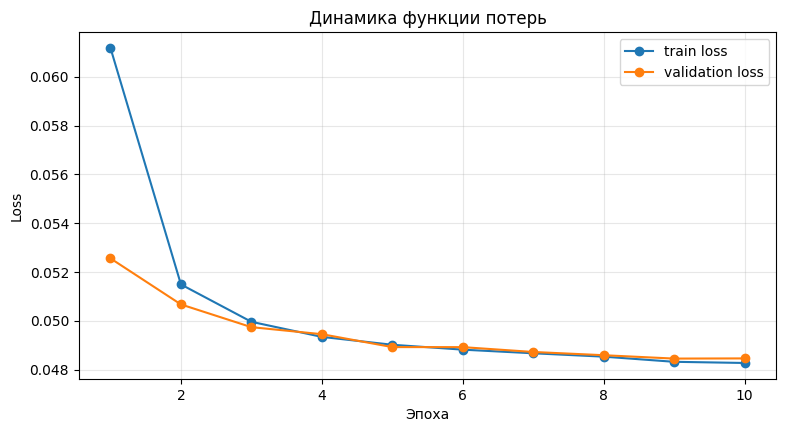

In [94]:
# Для каждой эпохи берём последнее доступное значение каждой метрики, пропуски игнорируются.
epoch_metrics = cvae_metrics.groupby("epoch")[["train_loss", "val_loss"]].last()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    epoch_metrics.index + 1, epoch_metrics["train_loss"], marker="o", label="train loss"
)
ax.plot(
    epoch_metrics.index + 1,
    epoch_metrics["val_loss"],
    marker="o",
    label="validation loss",
)
ax.set(xlabel="Эпоха", ylabel="Loss", title="Динамика функции потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Генерация изображений заданного класса

Для генерации задаём метку класса, выбираем случайный латентный вектор и передаём оба значения decoder. Сформируем метки `0, 1, ..., 9` и сгенерируем несколько примеров для каждого класса.

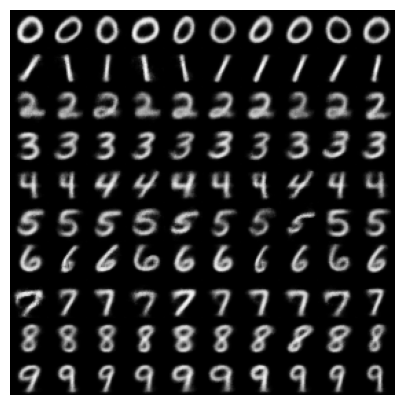

In [100]:
# Генерируем несколько изображений для каждого заданного класса MNIST.


def plot_samples(images: torch.Tensor, single_size: float = 1.0):
    count, digit_size, *_ = images.shape
    grid_size = int(count**0.5)

    images = images.reshape((grid_size, grid_size, digit_size, digit_size))

    figure = np.zeros((digit_size * grid_size, digit_size * grid_size))

    for i in range(grid_size):
        for j in range(grid_size):
            figure[
                j * digit_size : (j + 1) * digit_size,
                i * digit_size : (i + 1) * digit_size,
            ] = images[j][i]

    plt.figure(figsize=(single_size * grid_size, single_size * grid_size))
    plt.imshow(figure, cmap="gray")
    plt.axis("off")
    plt.show()


samples_per_class = 10

labels_to_generate = torch.arange(10, device=device).repeat_interleave(
    samples_per_class
)

generator = torch.Generator().manual_seed(SEED)
random_z = torch.randn(len(labels_to_generate), 16, generator=generator).to(device)

with torch.inference_mode():
    conditional_samples = (
        cvae_best_model.decode(random_z, labels_to_generate).cpu().squeeze(1)
    )

plot_samples(conditional_samples, single_size=0.5)

**Исследование.** Насколько часто CVAE генерирует изображение, похожее на заданный класс? Различаются ли варианты одной цифры? Есть ли случаи, когда условие соблюдается не полностью? Приведите примеры.

## Управление стилем и интерполяция в CVAE

Условие класса позволяет управлять тем, **какая цифра** должна быть сгенерирована. Латентный вектор может кодировать другие вариации: наклон, толщину штриха, форму петли и индивидуальный стиль написания.

Можно зафиксировать метку класса и менять `z`, интерполируя между двумя кодами. Тогда decoder получает одно и то же условие класса, но разные латентные векторы. Другой эксперимент - сохранить `z` и менять метку класса.

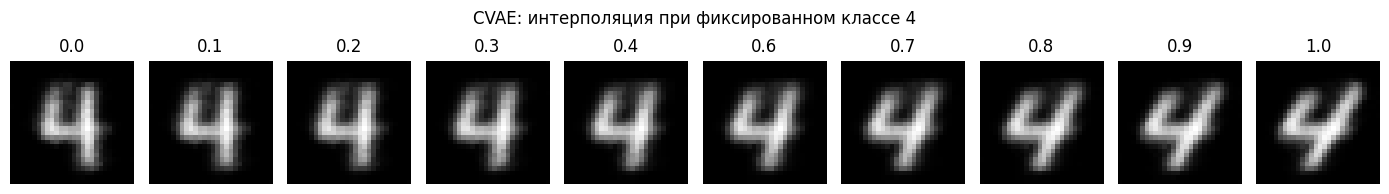

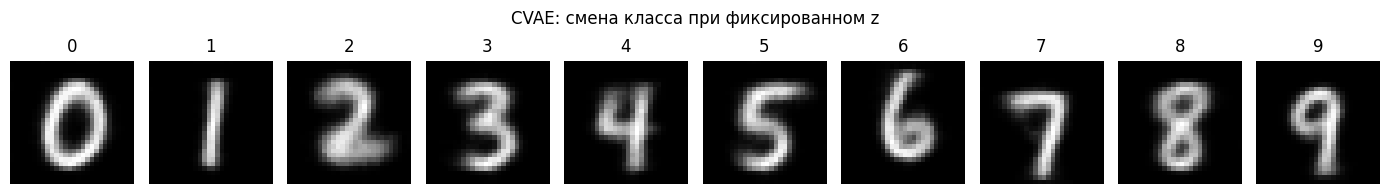

In [201]:
# Исследуем интерполяцию z при фиксированном классе и смену класса при фиксированном z.
fixed_digit = 4

generator = torch.Generator().manual_seed(8)  # Специально подобранный seed.
z1 = torch.randn(1, 16, generator=generator).to(device)
z2 = torch.randn(1, 16, generator=generator).to(device)

labels_same = torch.full((10,), fixed_digit, dtype=torch.long, device=device)
t_values = torch.linspace(0, 1, 10, device=device)
z_path = torch.cat([(1 - t) * z1 + t * z2 for t in t_values], dim=0)

with torch.inference_mode():
    style_path = cvae_best_model.decode(z_path, labels_same).cpu()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))

for i, ax in enumerate(axes):
    ax.imshow(style_path[i, 0], cmap="gray")
    ax.set_title(f"{t_values[i].item():.1f}")
    ax.axis("off")

plt.suptitle(f"CVAE: интерполяция при фиксированном классе {fixed_digit}")
plt.tight_layout()
plt.show()

fixed_z = torch.randn(1, 16, generator=generator).to(device).repeat(10, 1)
all_labels = torch.arange(10, device=device)

with torch.inference_mode():
    class_path = cvae_best_model.decode(fixed_z, all_labels).cpu()

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for digit, ax in enumerate(axes):
    ax.imshow(class_path[digit, 0], cmap="gray")
    ax.set_title(str(digit))
    ax.axis("off")

plt.suptitle("CVAE: смена класса при фиксированном z")
plt.tight_layout()
plt.show()

**Исследование.** Какие характеристики меняются при интерполяции `z` с фиксированной меткой? Можно ли уверенно назвать их «стилем»? Насколько устойчиво меняется класс при фиксированном `z` и изменении метки?

## Замена класса для изображений

CVAE позволяет не только генерировать новые изображения, но и **изменять класс уже существующего изображения**.

Для этого можно взять изображения одного класса из тестовой выборки, закодировать их в латентные векторы `z`, а затем передать decoder другие метки классов. При этом латентные векторы остаются неизменными - меняется только условие класса.

Таким образом, decoder получает информацию о том, какую цифру нужно сгенерировать, сохраняя при этом особенности исходного латентного представления.

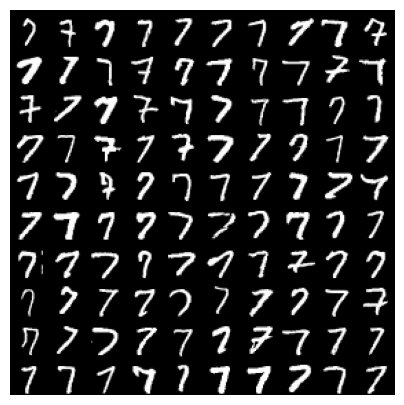

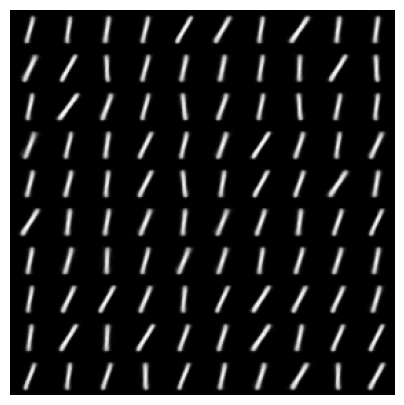

In [ ]:
# Берём изображения исходного класса, кодируем их в латентное пространство и повторно генерируем, передавая decoder метку другого класса.

# Выбираем для переноса визуально похожие классы изображений.
source_label = 7
destination_label = 1

samples = 10

# Находим индексы всех изображений исходного класса в тестовой выборке.
indices = torch.tensor(
    [i for i, (_, label) in enumerate(test_dataset) if label == source_label]
)

generator = torch.Generator().manual_seed(SEED)
selected_indices = indices[
    torch.randperm(len(indices), generator=generator)[: (samples * samples)]
]

# Выбираем samples * samples изображений
samples_dataset = Subset(test_dataset, selected_indices)

# Для всех изображений задаём одну и ту же целевую метку класса.
destination_labels = torch.full((samples * samples,), destination_label, device=device)

plot_samples(samples_dataset[...][0], single_size=0.5)

with torch.inference_mode():
    images, labels = collator(samples_dataset)

    # Кодируем изображения в латентные векторы.
    # Используем исходные метки, чтобы encoder получил правильное условие.
    codes, *_ = cvae_best_model.encode(images, labels)

    # Генерируем изображения с новыми метками, сохраняя исходные латентные векторы.
    generated = cvae_best_model.decode(codes, destination_labels)
    generated = generated.cpu().squeeze(1)

plot_samples(generated, single_size=0.5)

**Исследование.** Насколько хорошо модель сохраняет индивидуальные особенности исходного изображения при замене класса? Какие элементы исходной цифры переносятся в результат? Всегда ли decoder генерирует цифру, соответствующую новой метке?

## Контрольные вопросы

1. Чем задача AE отличается от классификации?
2. Почему автокодировщику нужен bottleneck?
3. Что такое encoder, decoder и латентный вектор?
4. Почему низкая MSE не всегда означает визуально идеальную реконструкцию?
5. Чем отличаются MaxUnpooling, Upsampling и `ConvTranspose2d`?
6. Почему обычный AE не гарантирует генерацию осмысленных изображений из случайных кодов?
7. Что предсказывает encoder в VAE?
8. Зачем нужен трюк репараметризации?
9. Какую роль играет KL-дивергенция?
10. Что произойдёт при слишком сильном KL-регуляризующем члене?
11. Чем отличаются латентные коды AE и VAE?
12. Что показывает PCA и почему она не объясняет семантику координат?
13. Чем CVAE отличается от VAE?
14. Как `nn.Embedding` представляет метку класса?
15. Как с помощью CVAE управлять классом генерируемого изображения?